# Champions Athletic Map

**University of San Diego · AAI 590 Capstone · Team 6**  
Aditi Jha, Beakal Zekaryas, and Saman (Sam) Tavasoli

We built a local prototype to help basketball players ages 13–17 organize a week of practice. An athlete might have team practice on Monday, two free evenings, and one skill they want to improve. Could a planner fit extra sessions around that schedule, keep existing commitments, and give the athlete enough detail to practice?

We studied three parts of that problem. Each has its own test and its own measure of success.

| Part of the project | What we tested | What we found |
|---|---|---|
| Exercise catalog (Steps 1–6) | We predicted the body-part label from an exercise name and description. We compared a majority baseline, logistic regression (L5), and a neural network (N3). | We selected L5 to suggest catalog labels. It matched 321 of 438 held-out labels (73.29%). |
| Reference search (Step 7) | We used the pretrained all-MiniLM-L6-v2 model to rank 11 short reference passages. | For the 24 held-out questions with a known relevant passage, the first five results included every passage marked relevant. |
| Weekly planning (Steps 8–9) | We gave four workflows using the same local language model, `llama3.1:8b`, the same 200 fictional athlete profiles. | Each workflow recorded 0 fully verified plans across the 150 feasible requests. We found scheduling mistakes in the calendars, and the automatic goal check was unfinished. |

Step 10 shows the calendar a fictional athlete received from our separate live application. Two saved runs of one dribbling request produced the same two-session draft. We report that example separately from the 800 study outcomes.

**Reading the results.** The tables, charts, calendars, and conclusions are saved in this notebook. Reading them requires no execution. To run the code, open the notebook in the project checkout with its Python environment, Unified data, and saved artifacts. New local predictions and plan generation are optional and switched off by default.

## Step 1 — Dataset loading and understanding

**Purpose.** What does one row represent? An exercise description, a food measurement, and a basketball season can each occupy one row. We count the different kinds of records and inspect a few examples before choosing data for the classifier.

**Input.** We use the frozen release in `data/unified/v1`. The CSV contains the records, `dataset_manifest.json` describes the fields and release, and `load_unified_dataset.py` opens and verifies it. The code works from the project root or its `notebooks` folder.

### Verify the dataset

We compare the CSV with the byte count and SHA-256 checksum in its manifest. A match tells us we are reading the same file our team used for the study.

In [1]:
from pathlib import Path
from runpy import run_path

import pandas as pd
from IPython.display import display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "unified" / "v1"
if not data_dir.is_dir():
    raise FileNotFoundError("Open the notebook from the project root or its notebooks folder.")

reader = run_path(str(data_dir / "load_unified_dataset.py"))
manifest = reader["load_manifest"]()
csv_path = data_dir / manifest["dataset_file"]
if csv_path.stat().st_size != manifest["csv_bytes"]:
    raise ValueError("The CSV size differs from the release. Check the Git LFS download.")

release = reader["verify_file"]()
if not release["file_matches_release"]:
    raise ValueError("The CSV checksum differs from the release manifest.")
print("Dataset:", csv_path.relative_to(project_root).as_posix())
print("Release:", release["dataset_id"])
print("SHA-256 matches the manifest:", release["file_matches_release"])

Dataset: data/unified/v1/champions_unified_dataset.csv
Release: champions-unified-132a2202b69046ae
SHA-256 matches the manifest: True


### Count the records

We read the header to identify all 24 fields, then load four columns. We count rows by `record_type`, trace them to a collection with `source_dataset`, and use `title` to show an example. The `classifier_use` field lets us choose an exercise from the training split. The detailed source records in `data_json` can stay on disk for now.

In [2]:
columns = pd.read_csv(csv_path, nrows=0, encoding="utf-8-sig").columns.tolist()
overview_fields = ["record_type", "source_dataset", "title", "classifier_use"]
overview = pd.read_csv(
    csv_path, usecols=overview_fields, dtype=str, keep_default_na=False, encoding="utf-8-sig"
)

if columns != list(manifest["columns"]) or len(overview) != manifest["row_count"]:
    raise ValueError("The CSV header or row count differs from the release manifest.")

type_counts = overview["record_type"].value_counts().rename_axis("Record type").to_frame("Rows")
print(f"{len(overview):,} rows × {len(columns)} columns in the full CSV")
print(f"{len(type_counts)} record types across {overview['source_dataset'].nunique()} source collections")
print("\nCSV columns in file order")
for start in range(0, len(columns), 6):
    print(", ".join(columns[start:start + 6]))
display(type_counts)

264,921 rows × 24 columns in the full CSV
14 record types across 9 source collections

CSV columns in file order
dataset_version, record_id, record_type, record_stage, title, text
source_dataset, source_record_id, source_file, source_row, source_sha256, source_url
split, split_group_id, target_label, class_index, classifier_use, retrieval_use
planner_status, food_lookup_use, review_status, protection_status, is_synthetic, data_json


,Rows
Record type,
nutrient_result,134267
food_sample_link,75055
basketball_season,24625
food_portion,10951
food,8204
player_career,4550
player_bio,3922
exercise,2909
athlete_profile,190


### Four examples from the dataset

The table shows the first eligible title in file order for each of four record types. For the exercise example, we use the training split. The source collection tells us where each title came from.

In [3]:
example_types = ["exercise", "basketball_resource", "reference_passage", "food"]
preview_allowed = overview["classifier_use"].isin(["training", "not_classifier_input"])
examples = overview.loc[
    preview_allowed & overview["record_type"].isin(example_types),
    ["record_type", "title", "source_dataset"],
]
examples = examples.drop_duplicates("record_type").set_index("record_type").loc[example_types]
examples = examples.rename_axis("Record type").rename(
    columns={"title": "Example", "source_dataset": "Source collection"}
)
with pd.option_context("display.max_colwidth", None):
    display(examples)

,Example,Source collection
Record type,,
exercise,Partner plank band row,original_cleaned_master
basketball_resource,1-2-3 Triple Threat,basketball_resource_release
reference_passage,Enjoyable activity routines and activity-specific safety,expanded_eleven_reference_corpus
food,"Hummus, commercial",additional_foundation_foods


### Results and observations

We loaded **264,921 rows and 24 columns**. Nutrient measurements were the largest group, with **134,267 rows**. Only **2,909 rows** described exercises. We used the split assigned to each exercise to determine its role in the classifier study.

The sample rows show why we kept the source collection alongside the title. *Partner plank band row* is a training exercise from the original cleaned master. *Hummus, commercial* is a Foundation food record. Later we use a separate field, `food_lookup_use`, to identify the foods selected for the planning prototype.

## Step 2 — Data cleaning and validation

**Purpose.** We trace the rows removed during the original cleaning, then check the IDs, missing values, and split assignments in the frozen release.

**Input.** We use the Unified CSV for the checks below. Its manifest contains the cleaning report for the nine original tables and a register of the source files available at the time.

### What we cleaned before building the Unified release

We standardized column names, trimmed and collapsed extra spaces, and removed exact duplicate rows. For exercises, we also removed rows without a name and converted categories such as body part and equipment to lowercase. These rules appear in our original `Champions Athletic data-cleaning pipeline.py` script. The report combines all removal reasons into a single count for each table.

In [4]:
history = pd.DataFrame(manifest["quality_reports"]["original_data_quality_audit"])
row_fields = ["source_rows", "clean_rows", "removed_rows"]
history[row_fields] = history[row_fields].astype(int)
cleaning = history.set_index("dataset")[row_fields].rename(columns={
    "source_rows": "Before", "clean_rows": "After", "removed_rows": "Removed"
})

print(f"Across {len(cleaning)} original tables, we went from {cleaning['Before'].sum():,} "
      f"to {cleaning['After'].sum():,} rows and removed {cleaning['Removed'].sum()}.")
display(cleaning.loc[cleaning["Removed"] > 0])

registered = pd.DataFrame(manifest["source_register"])
source_counts = registered["file_status"].value_counts().rename_axis("Recorded source status")
display(source_counts.to_frame("Entries"))

Across 9 original tables, we went from 256,412 to 256,337 rows and removed 75.


,Before,After,Removed
dataset,,,
exercise,2918,2909,9
basketball_season,24691,24625,66


,Entries
Recorded source status,
present,23
not_found_in_checked_locations,9
reference_not_downloaded,7


### Check record IDs and source details

Each row should have a unique record ID, a source collection, and a source record ID. We also read `data_json` one row at a time to check that the source details open as a JSON object. The table counts failures for each check.

In [5]:
import json

audit_fields = [
    "record_id", "record_type", "source_dataset", "source_record_id", "text",
    "classifier_use", "split", "split_group_id", "target_label", "class_index",
    "protection_status", "retrieval_use",
]
audit = pd.read_csv(csv_path, usecols=audit_fields, dtype=str,
                    keep_default_na=False, encoding="utf-8-sig")

def is_json_object(raw):
    try:
        return isinstance(json.loads(raw), dict)
    except json.JSONDecodeError:
        return False

invalid_payloads = sum(
    not is_json_object(row["data_json"]) for row in reader["iter_records"]()
)
integrity = pd.Series({
    "Missing record ID": audit["record_id"].str.strip().eq("").sum(),
    "Repeated record ID after its first appearance": audit["record_id"].duplicated().sum(),
    "Missing source collection or source ID": (
        audit["source_dataset"].str.strip().eq("") | audit["source_record_id"].str.strip().eq("")
    ).sum(),
    "Unreadable JSON or payload other than an object": invalid_payloads,
}, name="Rows flagged")
display(integrity.to_frame())
if integrity.any():
    raise ValueError("One or more record checks failed. See the flagged counts above.")

,Rows flagged
Missing record ID,0
Repeated record ID after its first appearance,0
Missing source collection or source ID,0
Unreadable JSON or payload other than an object,0


### Interpret missing values

Every training and validation exercise needs text. In the frozen CSV, held-out and excluded exercises have an empty top-level `text` field by design. We count blanks within each split to check that boundary.

For foods, a blank nutrient measurement means the value is unknown. We use the Foundation food report to count the missing fiber values and preserve the distinction between a missing measurement and a measured zero.

In [6]:
exercises = audit.loc[audit["record_type"] == "exercise"].copy()
exercises["blank_text"] = exercises["text"].str.strip().eq("")

text_by_split = exercises.groupby("split").agg(
    Exercises=("record_id", "size"), Blank_text=("blank_text", "sum")
)

food_quality = pd.DataFrame(manifest["quality_reports"]["foundation_field_quality_report"])
fiber = food_quality.set_index("column").loc["fiber_g"]
total_foods = int(fiber["missing"]) + int(fiber["non_missing"])
print(f"The saved Foundation report lists {fiber['missing']} of {total_foods} foods without a fiber value.")
display(text_by_split.reindex(["train", "validation", "test", "excluded"]))

The saved Foundation report lists 204 of 411 foods without a fiber value.


,Exercises,Blank_text
split,,
train,1999,0
validation,435,0
test,438,438
excluded,37,37


### Check body-part labels and held-out groups

We compare each scored exercise's body-part label with its number in the frozen class mapping. For example, **0** is the class number for *abdominals*. We also check that related exercises stayed in the same split. The protection flag applies to the whole group, including any excluded records in that group.

In [7]:
split_for_use = {"training": "train", "validation": "validation",
                 "reserved_test": "test", "excluded": "excluded"}
scored = exercises.loc[exercises["split"].isin(["train", "validation", "test"])]
class_map = manifest["classifier_context"]["label_mapping"]["class_to_index"]
expected_index = scored["target_label"].map({label: str(i) for label, i in class_map.items()})

development = exercises["split"].isin(["train", "validation"])
test_groups = exercises.loc[exercises["split"] == "test", "split_group_id"]
in_test_group = exercises["split_group_id"].isin(test_groups)
marked_protected = exercises["protection_status"].eq("protected_classifier_test_group")
splits_per_group = scored.groupby("split_group_id")["split"].nunique()

boundaries = pd.Series({
    "Split/use mismatch or missing group ID": (
        exercises["split"].ne(exercises["classifier_use"].map(split_for_use))
        | exercises["split_group_id"].str.strip().eq("")
    ).sum(),
    "Missing or mismatched scored label/index pair": scored["class_index"].ne(expected_index).sum(),
    "Training or validation exercise with blank text": (development & exercises["blank_text"]).sum(),
    "Held-out or excluded exercise with visible text": (~development & ~exercises["blank_text"]).sum(),
    "Groups appearing in multiple scored splits": splits_per_group.gt(1).sum(),
    "Incorrect held-out group protection flag": marked_protected.ne(in_test_group).sum(),
    "Held-out group record missing retrieval protection": (
        in_test_group & exercises["retrieval_use"].ne("protected_not_indexed")
    ).sum(),
}, name="Cases flagged")
print(f"We checked {len(scored):,} scored exercises and identified "
      f"{in_test_group.sum()} exercise records in held-out groups.")
display(boundaries.to_frame())
if boundaries.any():
    raise ValueError("One or more exercise checks failed. See the flagged counts above.")

We checked 2,872 scored exercises and identified 439 exercise records in held-out groups.


,Cases flagged
Split/use mismatch or missing group ID,0
Missing or mismatched scored label/index pair,0
Training or validation exercise with blank text,0
Held-out or excluded exercise with visible text,0
Groups appearing in multiple scored splits,0
Incorrect held-out group protection flag,0
Held-out group record missing retrieval protection,0


### Results and observations

- **Original cleaning.** The nine tables went from **256,412 to 256,337 rows**. We removed nine exercise rows and 66 basketball-season rows. We later added other collections to build the **264,921-row** Unified release.
- **Record integrity.** Every Unified row had a unique, nonblank record ID, both source identifiers, and a readable JSON object. All **2,872** scored exercises matched the saved label mapping. No exercise group appeared in more than one scored split.
- **Missing values.** All **2,434** training and validation exercises had text. The **438** held-out exercises and **37** excluded exercises had blank top-level text. The **439** protected records include the 438 held-out exercises and one excluded exercise from a held-out group. We kept **204** missing fiber measurements as unknown.
- **Source coverage.** When we registered the sources, **23** files were present, **9** inputs were missing from the locations checked, and **7** publisher references had not been downloaded. We could check the frozen release directly. The missing originals limit what we can verify about the earlier cleaning.

## Step 3 — Exploratory data analysis

**Purpose.** We look at what the rows represent, how often each body-part label appears, which food measurements are missing, and how many resources reached each stage of preparation.

**Input.** We use the Unified release from Steps 1 and 2. For the exercise-label chart, we count only the frozen training split.

### What makes up most of the dataset?

We plot the three largest record types and the exercise records on the same scale. The last bar combines the other ten types.

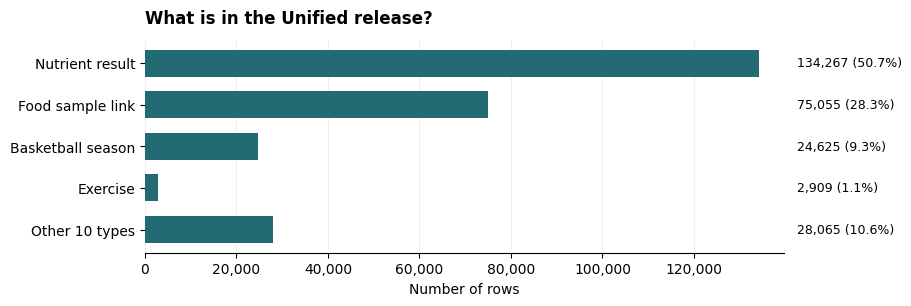

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

def bar_chart(values, title, axis_label, labels, *, percent=False):
    height = max(2.8, 1.25 + 0.34 * len(values))
    fig, ax = plt.subplots(figsize=(9, height), layout="constrained")
    ax.barh(values.index, values, color="#226b75", height=0.65)
    ax.invert_yaxis()
    ax.set_xlim(0, 100 if percent else values.max() * 1.04)
    ax.set_xlabel(axis_label)
    ax.set_title(title, loc="left", fontweight="bold", pad=12)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    for y, label in enumerate(labels):
        ax.text(1.02, y, label, transform=ax.get_yaxis_transform(), va="center", fontsize=9)
    plt.show()

record_counts = overview["record_type"].value_counts()
shown = pd.concat([record_counts.head(3), record_counts.loc[["exercise"]]])
remaining_types = len(record_counts) - len(shown)
shown.loc[f"other {remaining_types} types"] = len(overview) - shown.sum()
shown.index = shown.index.str.replace("_", " ").str.capitalize()
labels = [f"{n:,} ({n / len(overview):.1%})" for n in shown]
bar_chart(shown, "What is in the Unified release?", "Number of rows", labels)

Nutrient measurements and food-sample links account for **209,322 of 264,921 rows (79.0%)**. Exercises account for **2,909 rows (1.1%)**, and only the training portion of those exercises was available to fit the classifiers.

### How balanced are the body-part labels in training?

We count the training exercises for each label and order them from most to least common.

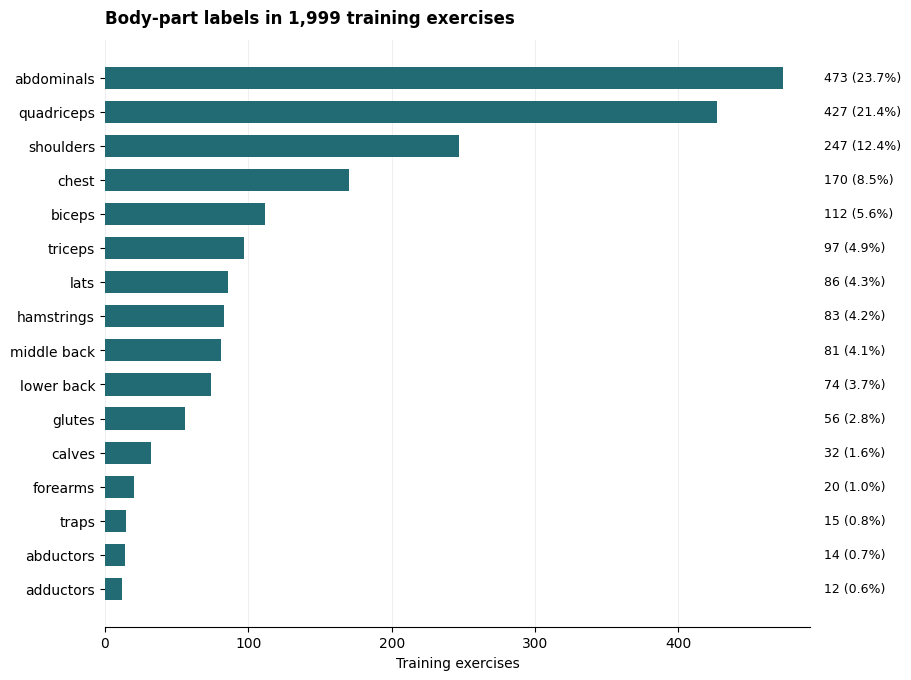

In [9]:
training_rows = exercises.loc[exercises["classifier_use"] == "training"]
class_counts = training_rows["target_label"].value_counts()
labels = [f"{n:,} ({n / len(training_rows):.1%})" for n in class_counts]
bar_chart(class_counts, f"Body-part labels in {len(training_rows):,} training exercises",
          "Training exercises", labels)

Abdominals (473) and quadriceps (427) account for **900 of 1,999 training exercises (45.0%)**. Adductors have only **12** examples. This imbalance is why we report **macro-F1** alongside accuracy. Macro-F1 gives each of the 16 body-part classes the same weight when averaging their F1 scores.

### Which nutrients have the most missing measurements?

We compare protein, fat, carbohydrate, and fiber for the same 411 Foundation foods. We count blanks as missing and keep recorded zeros.

Foods with a recorded fiber value of zero: 8


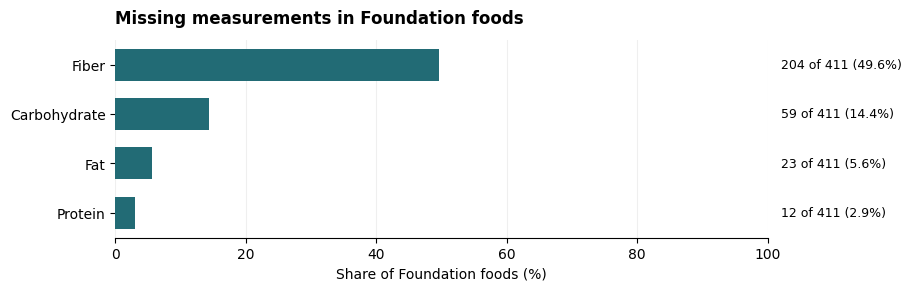

In [10]:
foundation_rows = reader["iter_records"](source_dataset="additional_foundation_foods", decode_data=True)
foundation = pd.DataFrame(row["data_json"]["source_record"] for row in foundation_rows)
nutrient_names = {"protein_g": "Protein", "fat_g": "Fat",
                  "carbohydrate_g": "Carbohydrate", "fiber_g": "Fiber"}
nutrients = foundation[list(nutrient_names)].replace("", float("nan")).apply(pd.to_numeric)
missing = nutrients.rename(columns=nutrient_names).isna().sum().sort_values(ascending=False)
missing_pct = 100 * missing / len(foundation)
labels = [f"{n} of {len(foundation)} ({pct:.1f}%)" for n, pct in zip(missing, missing_pct)]
print(f"Foods with a recorded fiber value of zero: {nutrients['fiber_g'].eq(0).sum()}")
bar_chart(missing_pct, "Missing measurements in Foundation foods",
          "Share of Foundation foods (%)", labels, percent=True)

Fiber is missing for **204 of 411 foods (49.6%)** and protein for **12 (2.9%)**. Another **8 foods** have a measured fiber value of zero. Filling all the blanks with zero would erase that difference.

### Which resources were ready for planning?

Each bar uses the count for its own collection as the denominator. We use the status recorded in the Unified manifest. The food bar covers the SR Legacy collection, while the missing-nutrient chart above covers Foundation foods.

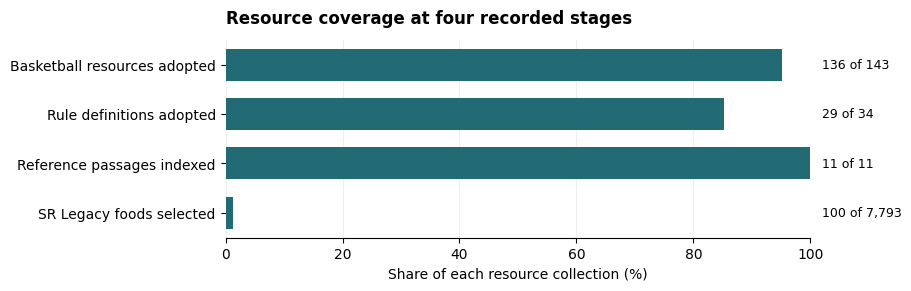

In [11]:
counts = manifest["counts"]
types = counts["record_type"]
planner = counts["planner_status"]
rows = [
    ("Basketball resources adopted", planner["prototype_adopted_activation_pending"],
     types["basketball_resource"]),
    ("Rule definitions adopted", planner["prototype_definition_adopted_validator_not_ready"],
     types["planning_rule"]),
    ("Reference passages indexed", counts["retrieval_use"]["indexed_reference"],
     types["reference_passage"]),
    ("SR Legacy foods selected", counts["food_lookup_use"]["prepared_selected_reference_activation_unverified"],
     counts["source_dataset"]["usda_sr_legacy_2018"]),
]
coverage = pd.DataFrame(rows, columns=["Recorded stage", "With status", "In collection"])
coverage = coverage.set_index("Recorded stage")
share = 100 * coverage["With status"] / coverage["In collection"]
labels = coverage["With status"].map("{:,}".format) + " of " + coverage["In collection"].map("{:,}".format)
bar_chart(share, "Resource coverage at four recorded stages",
          "Share of each resource collection (%)", labels, percent=True)

### Results and observations

We adopted **136 of 143** basketball resources for the prototype. Activation was still pending in the release record. We also adopted **29 of 34** rule definitions, although their automatic checks were still pending. All **11 reference passages** were indexed. We selected **100 of 7,793 SR Legacy foods** for lookup. The release records that selection but leaves activation unverified. Steps 7 and 8 show which resources actually reached a planner in a saved run.

For the classifier, the imbalance in the **1,999 training exercises** matters. An overall accuracy score can hide poor results on rare body-part labels. We keep that in mind when comparing models in Steps 5 and 6.

## Step 4 — Feature preparation and existing data splits

**Purpose.** Our classifiers read an exercise name and, when available, its description. Both try to predict the body-part label recorded in the dataset. We follow one training exercise through two ways of turning that text into numbers.

### What do L5 and N3 mean?

We used **L** for our logistic regression experiments and **N** for our neural network experiments. The number identifies the training configuration within that family.

- **Logistic regression (L5)** learns how much individual words and adjacent word pairs contribute to each of the 16 possible body-part labels.
- **Neural network (N3)** looks up a learned vector for each token, averages the vectors, and uses the result to score the same 16 labels.

One saved validation example shows why we compared them. The recorded label for *Dumbbell biceps curl to upright row* was **biceps**. L5 predicted **biceps** and N3 predicted **middle back**. In Step 5 we compare all validation exercises and explain why we chose L5 for catalog tagging. A separate model, `llama3.1:8b`, generated the athlete plans.

**Input.** We use the exercise rows from `data/unified/v1`, the frozen classifier package, and the saved L5 feature summary. The package contains the vocabularies learned on the training split and the text-processing rules used in the experiment.

### Which exercises go into each split?

We kept related exercises together by `split_group_id`. We shuffled whole groups and aimed for 70% training, 15% validation, and 15% test. We considered both split size and the balance of body-part labels when choosing the original assignment.

Here we read those saved assignments. The percentages use the **2,872 scored exercises** as their denominator. We count the 37 excluded exercises separately.

In [12]:
split_order = ["train", "validation", "test"]
membership = exercises.loc[exercises["split"].isin(split_order), ["split", "split_group_id"]]
split_summary = membership.groupby("split").agg(
    Exercises=("split_group_id", "size"), Groups=("split_group_id", "nunique")
).loc[split_order]
split_summary["Share of scored exercises"] = (
    split_summary["Exercises"].div(len(membership)).map("{:.2%}".format)
)
groups_in_multiple_splits = membership.groupby("split_group_id")["split"].nunique().gt(1).sum()
print(f"Excluded exercises: {exercises['split'].eq('excluded').sum()}")
print(f"Groups shared across scored splits: {groups_in_multiple_splits}")
display(split_summary)

Excluded exercises: 37
Groups shared across scored splits: 0


,Exercises,Groups,Share of scored exercises
split,,,
train,1999,1794,69.60%
validation,435,384,15.15%
test,438,385,15.25%


### Which fields do the classifiers use?

| Role | Unified field | How we use it |
|---|---|---|
| Input (X) | `text` | The exercise name followed by its description, when available. Some exercises have only a name. |
| Target (y) | `target_label` | The recorded body-part category. The matching `class_index` is a number from 0 to 15. |
| Split controls | `classifier_use`, `split`, `split_group_id`, `protection_status` | Identify the assigned records and check that related exercises stay together. |

We use the record ID to keep each exercise paired with its label. Only `text` goes into the models. The source columns and `data_json` may contain archived labels, so we leave them out of the features. For held-out exercises, we use the saved split information here. Their top-level text stays blank.

In [13]:
def classifier_inputs(use):
    selected = exercises["classifier_use"].eq(use)
    rows = exercises.loc[selected, ["record_id", "text", "target_label"]].set_index("record_id")
    return rows["text"], rows["target_label"]

X_train, y_train = classifier_inputs("training")
X_valid, y_valid = classifier_inputs("validation")
example_id = X_train.index[0]
sample_text, sample_label = X_train.loc[example_id], y_train.loc[example_id]
name, _, description = sample_text.partition("\n\n")

print(f"Training pairs: {len(X_train):,}    Validation pairs: {len(X_valid):,}")
print("Exercise name:", name)
print("Description:", description)
print(f"Saved target: {sample_label} (class {class_map[sample_label]})")

Training pairs: 1,999    Validation pairs: 435
Exercise name: Partner plank band row
Description: The partner plank band row is an abdominal exercise where two partners perform single-arm planks while pulling on the opposite ends of an exercise band. This technique can be done for time or reps in any ab-focused workout.
Saved target: abdominals (class 0)


### How does L5 represent the exercise?

Our majority baseline always predicts *abdominals*, the most frequent training label. L5 learns from the words in the exercise text. We use **TF-IDF** (term frequency–inverse document frequency) to assign weights to words and adjacent word pairs. If two terms occur equally often in an exercise, the term that appears in fewer training descriptions generally gets more weight.

The saved matrix summary has one row per split. Within each underlying matrix, a row represents an exercise and a column represents a term in the training vocabulary. An all-zero row means the exercise contributed no recognized terms.

In [14]:
diagnostics_path = project_root / "artifacts/tuning/runs/L5_seed42/feature_diagnostics.csv"
l5_matrices = pd.read_csv(diagnostics_path).set_index("split")
display(l5_matrices[["records", "feature_columns", "nonzero_values", "zero_vector_records"]]
        .rename(columns={"records": "Exercises", "feature_columns": "Features",
                         "nonzero_values": "Nonzero weights", "zero_vector_records": "All-zero rows"}))

,Exercises,Features,Nonzero weights,All-zero rows
split,,,,
train,1999,10000,91261,10
validation,435,10000,17649,2


For *Partner plank band row*, we verify the saved classifier files and use the fitted vectorizer to calculate the five highest TF-IDF weights. This calculation requires the package versions recorded with L5. The saved matrix summary above can be read in any environment that can open the CSV.

In [15]:
import hashlib
import sys
from importlib.metadata import PackageNotFoundError, version

bundle = project_root / "artifacts/classifiers/exercise-classifier-4f6b6f435ef52fef8f4cca6d"
identity = json.loads((bundle / "manifest.json").read_text(encoding="utf-8"))["identity"]

def checked_file(relative):
    path = bundle / relative
    expected_digest = identity["payloads"][relative]["sha256"]
    actual_digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(f"The saved classifier file has changed: {relative}")
    return path

project_src = str(project_root / "src")
if project_src not in sys.path:
    sys.path.insert(0, project_src)
from champion_athletic_map import text_preprocessing as text_tools

expected_source = checked_file("src/champion_athletic_map/text_preprocessing.py")
if Path(text_tools.__file__).read_bytes() != expected_source.read_bytes():
    raise ValueError("The imported text rules differ from the frozen classifier package.")

versions = identity["dependencies"]["packages"]
try:
    l5_stack_matches = all(version(p) == versions[p] for p in ("scikit-learn", "joblib", "numpy", "scipy"))
except PackageNotFoundError:
    l5_stack_matches = False

In [16]:
if l5_stack_matches:
    import joblib

    model_path = identity["artifacts"]["logistic_regression"]["relative_path"]
    vectorizer = joblib.load(checked_file(model_path)).named_steps["tfidf"]
    weights = vectorizer.transform([sample_text]).tocsr()
    active_terms = pd.DataFrame({
        "Term": vectorizer.get_feature_names_out()[weights.indices],
        "TF-IDF weight": weights.data,
    })
    strongest = active_terms.sort_values(["TF-IDF weight", "Term"], ascending=[False, True])
    print(f"{weights.nnz} nonzero weights in {weights.shape[1]:,} feature columns")
    display(strongest.head(5).round(4).reset_index(drop=True))
else:
    requirements = (bundle / "requirements.txt").relative_to(project_root)
    print(f"The TF-IDF preview uses the package versions listed in {requirements}.")

64 nonzero weights in 10,000 feature columns


,Term,TF-IDF weight
0,band row,0.3034
1,partner plank,0.3034
2,plank band,0.3034
3,band,0.2665
4,partner,0.2316


### How does N3 represent the same exercise?

We normalize Unicode, spacing, and case, then look up each token in the training vocabulary. Token ID **1** stands for an unknown token. We keep up to **81 tokens** per exercise. When combining exercises into a batch, we pad shorter sequences on the right with ID **0** and ignore those positions when averaging. The token vocabulary and body-part labels have separate numbering systems.

In [17]:
feature_config = manifest["classifier_context"]["preprocessing_config"]
sequence_limit = feature_config["sequence_settings"]["max_sequence_length"]
vocabulary = json.loads(checked_file("config/vocabulary.json").read_text(encoding="utf-8"))
tokens = text_tools.prepare_canonical_text(sample_text)["tokens"]
encoded = text_tools.encode_neural_tokens(tokens, vocabulary, sequence_limit)

print(f"Vocabulary entries including padding and unknown: {vocabulary['vocabulary_size']:,}")
print(f"Tokens retained: {encoded['retained_length']} of {encoded['raw_token_count']}"
      f" (limit {sequence_limit})")
display(pd.DataFrame({"First four tokens": tokens[:4], "N3 token ID": encoded["token_ids"][:4]}))

Vocabulary entries including padding and unknown: 1,748
Tokens retained: 42 of 42 (limit 81)


,First four tokens,N3 token ID
0,partner,258
1,plank,65
2,band,107
3,row,70


### Results and observations

For *Partner plank band row*, the recorded label is **abdominals (class 0)**. L5 produced **64 nonzero weights across 10,000 possible features**. Its highest-weighted word pairs were *band row*, *partner plank*, and *plank band*, each at **0.3034**. These weights describe the input text. The model uses learned coefficients to turn those inputs into class scores. N3 kept all **42 tokens**. Its first four token IDs, **258, 65, 107, and 70**, correspond to *partner*, *plank*, *band*, and *row*.

All three classifiers used the same split. We learned the baseline label frequencies, L5's vocabulary and inverse-document-frequency weights, and N3's vocabulary from the **1,999 training exercises**. We used the **435 validation exercises** for model selection and reserved the **438 held-out exercises** for the evaluation in Step 6.

## Step 5 — Machine-learning model development

**Purpose.** Can exercise text tell us more about the recorded body part than we would learn by always guessing the most common label? We tested a majority baseline, a logistic regression classifier, and a neural network on the same 16 labels.

**Input.** We used the 1,999 training exercises to fit the models and the 435 validation exercises to choose settings. The tables below come from the original runs in `results/tuning/`. The code excerpts show how we trained the models. The executable cells read the saved results.

### The baseline and logistic regression

The majority baseline always predicts *abdominals*, the most frequent training label. The zeros in its input just give scikit-learn one row per exercise. Logistic regression uses the TF-IDF features from Step 4. For each body part, it learns a weight for each word or word pair.

The following excerpt shows the training calls from the original notebook. `targets` contains the body-part labels as integers. We used the same text settings for all six logistic regression candidates.

```python
majority = DummyClassifier(strategy="most_frequent", random_state=42)
majority.fit(np.zeros((len(targets), 1)), targets)

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**vectorizer_kwargs)),
    ("classifier", LogisticRegression(**classifier_kwargs)),
])
pipeline.fit(train_texts, targets)
```

We tried three values of `C` (0.1, 1, and 10), each with and without balanced class weights. A larger `C` lets the model fit the training data more closely by penalizing large coefficients less. Balanced weights give exercises from rare classes more influence during training. We reused our earlier unweighted fit with `C=1` as candidate L2.

In [18]:
results_dir = project_root / "results"
tuning_dir = results_dir / "tuning"
selection = json.loads(checked_file("config/model_selection.json").read_text(encoding="utf-8"))

majority_label = y_train.value_counts().idxmax()
print(f"Baseline prediction: {majority_label} ({y_train.eq(majority_label).sum()} of {len(y_train):,} training labels)")

runs = selection["run_counts"]
print(f"Logistic and neural tuning outcomes: {runs['completed_or_reused_outcomes']} completed or reused, "
      f"{runs['failed_outcomes']} failed.")

logistic = pd.read_csv(tuning_dir / "logistic_validation_metrics.csv", keep_default_na=False)
logistic["class_weight"] = logistic["class_weight"].replace("", "none")
display(logistic.set_index("candidate_id")[["C", "class_weight", "accuracy", "macro_f1"]]
        .rename(columns={"class_weight": "Class weights", "accuracy": "Validation accuracy",
                         "macro_f1": "Validation macro-F1"}).round(6))

Baseline prediction: abdominals (473 of 1,999 training labels)
Logistic and neural tuning outcomes: 14 completed or reused, 0 failed.


,C,Class weights,Validation accuracy,Validation macro-F1
candidate_id,,,,
L0,0.1,none,0.468966,0.146453
L1,0.1,balanced,0.627586,0.527872
L2,1.0,none,0.708046,0.470967
L3,1.0,balanced,0.703448,0.573719
L4,10.0,none,0.728736,0.557628
L5,10.0,balanced,0.724138,0.598009


L4 had the highest validation accuracy (72.87%). We selected **L5**, which had slightly lower accuracy (72.41%) and the highest validation macro-F1 (**0.598009**). Macro-F1 gives each of our 16 body parts equal weight, including the least common ones. L5 used `C=10`, balanced class weights, L2 regularization, the LBFGS solver, seed 42, and a 1,000-iteration limit.

### The neural network

N3 learned 64 numbers for each token. It averaged the vectors for the words in an exercise, skipping padding, then passed the average through a 64-unit hidden layer with ReLU to produce 16 class scores. Two descriptions with the same retained tokens in a different order produce the same average. During training we used 20% dropout, AdamW, a learning rate of 0.001, weight decay of 0.0001, batches of 32, and class-weighted cross-entropy. The network is defined in `src/champion_athletic_map/neural_classifier.py`.

Each training batch updated the weights as follows.

```python
optimizer.zero_grad(set_to_none=True)
logits = model(input_ids, mask)
loss = criterion(logits, targets)
loss.backward()
optimizer.step()
```

We tried four neural configurations at seed 42, varying learning rate, dropout, or class weights. We trained the two strongest candidates (N3 and N0) again at seeds 17 and 73 and compared their mean validation macro-F1 across the three seeds. We had chosen seed 42 in advance for the checkpoint we would keep.

In [19]:
seeds = pd.read_csv(tuning_dir / "neural_seed_summary.csv").set_index("candidate_id")
display(seeds[["macro_f1_seed42", "macro_f1_seed17", "macro_f1_seed73", "mean_macro_f1"]]
        .rename(columns={"macro_f1_seed42": "Seed 42", "macro_f1_seed17": "Seed 17",
                         "macro_f1_seed73": "Seed 73", "mean_macro_f1": "Mean validation macro-F1"})
        .round(6))

,Seed 42,Seed 17,Seed 73,Mean validation macro-F1
candidate_id,,,,
N3,0.571145,0.553626,0.562598,0.562456
N0,0.540130,0.555869,0.510216,0.535405


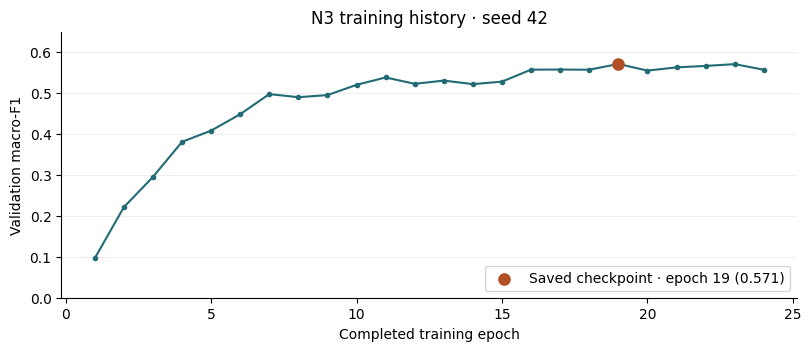

In [20]:
n3_history = pd.read_csv(tuning_dir / "selected_neural_learning_history.csv").sort_values("epoch")
best_epoch = int(seeds.loc["N3", "primary_best_epoch"])
best_score = n3_history.set_index("epoch").loc[best_epoch, "validation_macro_f1"]

fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
ax.plot(n3_history["epoch"], n3_history["validation_macro_f1"], marker="o", ms=3, color="#226b75")
ax.scatter(best_epoch, best_score, color="#b14e24", s=65, zorder=3,
           label=f"Saved checkpoint · epoch {best_epoch} ({best_score:.3f})")
ax.set(xlabel="Completed training epoch", ylabel="Validation macro-F1",
       title="N3 training history · seed 42", ylim=(0, 0.65))
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right")
plt.show()

N3 had the stronger three-seed mean (**0.562456**). In the seed-42 run shown above, its best validation score came at **epoch 19**. Training stopped at epoch 24 after five epochs without improvement.

To choose our catalog tagger, we compared the fitted models on the same validation exercises. L5 scored **0.598009** on macro-F1, compared with **0.571145** for the selected N3 checkpoint and **0.020029** for the baseline. We kept L5 as originally fitted on the training set.

### How did the models label the same exercise?

We matched two saved validation predictions per learned model to the original exercise records using their catalog IDs. The table also shows what the baseline guessed. The three models disagree on the first exercise. On the second, L5 and N3 agree with each other and both miss the recorded body part.

In [21]:
example_titles = ["Dumbbell biceps curl to upright row", "Band Hip Adductions"]
case_records = []
for row in reader["iter_records"](classifier_use="validation"):
    if row["title"] in example_titles:
        catalog_id = json.loads(row["data_json"])["catalog_record"]["catalog_id"]
        case_records.append({
            "catalog_id": catalog_id,
            "Exercise": row["title"],
            "Recorded label": row["target_label"],
            "record_id": row["record_id"],
        })

case_records = pd.DataFrame(case_records).set_index("catalog_id", verify_integrity=True)
evidence = pd.read_csv(tuning_dir / "selected_validation_predictions.csv")
matched = evidence.loc[evidence["catalog_id"].isin(case_records.index)]
labels_match = matched["target_label"].eq(matched["catalog_id"].map(case_records["Recorded label"]))
if len(case_records) != len(example_titles) or not labels_match.all():
    raise ValueError("The saved examples and Unified validation labels differ.")
predictions = matched.pivot(index="catalog_id", columns="comparison_role", values="predicted_label")
predictions = predictions.rename(columns={"majority_class": "Majority", "selected_logistic": "L5",
                                          "selected_neural": "N3"})
exercise_examples = case_records.join(predictions, validate="one_to_one").set_index("Exercise").loc[example_titles]
if exercise_examples[["Majority", "L5", "N3"]].isna().any().any():
    raise ValueError("A saved prediction is missing.")
display(exercise_examples[["Recorded label", "Majority", "L5", "N3"]])

,Recorded label,Majority,L5,N3
Exercise,,,,
Dumbbell biceps curl to upright row,biceps,abdominals,biceps,middle back
Band Hip Adductions,adductors,abdominals,glutes,glutes


### Where we used L5

We used L5 to suggest body-part labels for team review of the training and validation catalog records. A match on a training exercise tells us less about generalization because the model learned from that exercise. We kept the original labels alongside our suggestions, including disagreements. Choosing which basketball drills could go into a plan was a separate decision.

In [22]:
tagging = json.loads((results_dir / "step22_catalog_tagging_summary.json").read_text(encoding="utf-8"))
previews = pd.DataFrame(tagging["development_preview_counts"]).set_index("split")
print("Selected tagger:", selection["tagging_model"]["candidate_id"])
print(f"Saved L5 catalog suggestions: {previews['suggestions_produced'].sum():,}")
print("Source labels changed:", tagging["source_labels_changed"])
print("Planner eligibility granted:", tagging["planner_eligibility_granted"])
display(previews[["suggestions_produced", "source_agreement_records", "source_disagreement_records"]]
        .rename(columns={"suggestions_produced": "Suggestions", "source_agreement_records": "Matched source",
                         "source_disagreement_records": "Differed from source"}))

Selected tagger: L5
Saved L5 catalog suggestions: 2,434
Source labels changed: False
Planner eligibility granted: False


,Suggestions,Matched source,Differed from source
split,,,
train,1999,1898,101
validation,435,315,120


**Optional prediction.** The table above contains saved validation results. With the package versions from Step 4, setting `RUN_ONE_L5_PREDICTION` to `True` runs the fitted model on the first example and prints the fresh prediction beside the saved one.

In [23]:
RUN_ONE_L5_PREDICTION = False

if RUN_ONE_L5_PREDICTION:
    if not l5_stack_matches:
        raise RuntimeError("Use the package versions listed in the frozen classifier bundle for this replay.")
    import joblib

    sample_id = exercise_examples.loc[example_titles[0], "record_id"]
    frozen_l5 = joblib.load(checked_file(identity["artifacts"]["logistic_regression"]["relative_path"]))
    class_id = int(frozen_l5.predict([X_valid.loc[sample_id]])[0])
    new_label = identity["class_order"][class_id]
    print(f"New L5 replay for {example_titles[0]}: {new_label}")
    print("Saved L5 prediction:", exercise_examples.loc[example_titles[0], "L5"])
else:
    print("Optional replay is off. The comparison shows saved validation predictions.")

Optional replay is off. The comparison shows saved validation predictions.


### Results and observations

Our tuning table contains **14 results** across the logistic and neural settings and seeds. We fitted 12 runs during tuning and reused two earlier runs. All 14 have results. L5 suggested body-part labels for **2,434 development exercises**. On *Band Hip Adductions*, both L5 and N3 predicted *glutes*. The source listed *adductors*.

We used the validation exercises several times to compare model settings and choose L5. Step 6 measures how that choice held up on the 438 exercises we set aside for the test.

## Step 6 — Machine-learning evaluation and comparison

**Purpose.** We chose L5 on the validation set. How often did it match the recorded body-part label on exercises held out from training and model selection?

**Input.** We use the split assignments and recorded labels from Step 4, the validation predictions in `results/tuning/`, and the held-out evaluation listed in `results/classifier_test/selected_evaluation.json`. We compare the majority baseline, L5 logistic regression, and the N3 neural network at its selected checkpoint (seed 42, epoch 19).

### Match the saved predictions to the splits

For each exercise, we read its recorded label and the three model predictions. We check that exercise counts match the frozen split for each group and body part. We can score the predictions from those labels alone.

In [24]:
selected_test = json.loads((results_dir / "classifier_test/selected_evaluation.json").read_text(encoding="utf-8"))
test_dir = (project_root / selected_test["manifest_path"]).parent
label_order = manifest["classifier_context"]["label_mapping"]["class_order"]
model_names = {"majority_class": "Majority baseline", "tfidf_logistic_regression": "L5", "neural_classifier": "N3"}
metadata_cols = ["catalog_id", "split_group_id", "target_label"]

valid_long = pd.read_csv(tuning_dir / "selected_validation_predictions.csv",
                         usecols=metadata_cols + ["model_id", "predicted_label"])
valid_saved = (valid_long.pivot(index=metadata_cols, columns="model_id", values="predicted_label")
               .rename(columns=model_names).reset_index())
test_columns = {"majority_predicted_label": "Majority baseline",
                "logistic_regression_predicted_label": "L5", "neural_predicted_label": "N3"}
test_saved = pd.read_csv(test_dir / "predictions.csv", usecols=metadata_cols + list(test_columns)).rename(columns=test_columns)

saved_splits = {"validation": valid_saved, "test": test_saved}
for split, rows in saved_splits.items():
    expected = exercises.loc[exercises["split"].eq(split)]
    group_label = ["split_group_id", "target_label"]
    pd.testing.assert_series_equal(rows.groupby(group_label).size(), expected.groupby(group_label).size())
    assert rows["catalog_id"].is_unique and rows[list(model_names.values())].isin(label_order).all().all()
    print(f"{split.capitalize()}: {len(rows)} exercises in {rows['split_group_id'].nunique()} groups.")

Validation: 435 exercises in 384 groups.
Test: 438 exercises in 385 groups.


### Score the three models

**Accuracy** counts how often a prediction matches the recorded label. **Macro-F1** gives each body part an equal vote. For each label, precision asks how often the model was right when it predicted that label. Recall asks how many exercises with that label the model found. F1 combines the two, and we average the 16 F1 scores. That way *adductors* counts as much as *abdominals* even though it occurs far less often.

We calculate each label's F1 from the confusion matrix. We double the number of correct predictions for the label and divide by the sum of its recorded count and its predicted count. When both counts are zero, we assign F1 a value of zero, following our original scoring rule. We check the resulting metrics against the saved validation and test scores.

In [25]:
recorded_scores = {
    "validation": pd.read_csv(tuning_dir / "selected_validation_metrics.csv").set_index("model_id"),
    "test": pd.read_csv(test_dir / "metrics.csv").set_index("model_id"),
}
matrices, comparison_rows = {}, []
for model_id, name in model_names.items():
    result = {"Model": name}
    for split, rows in saved_splits.items():
        counts = pd.crosstab(rows["target_label"], rows[name]).reindex(
            index=label_order, columns=label_order, fill_value=0)
        matrices[split, name] = counts
        hits = pd.Series(counts.to_numpy().diagonal(), index=label_order)
        denominator = counts.sum(axis=1) + counts.sum(axis=0)
        f1_by_label = (2 * hits).div(denominator.where(denominator.gt(0))).fillna(0)
        accuracy, macro_f1 = hits.sum() / len(rows), f1_by_label.mean()

        saved = recorded_scores[split].loc[model_id]
        assert int(saved["records"]) == len(rows) and int(saved["groups"]) == rows["split_group_id"].nunique()
        assert abs(accuracy - saved["accuracy"]) < 1e-10 and abs(macro_f1 - saved["macro_f1"]) < 1e-10
        result[f"{split} correct"] = f"{hits.sum()} / {len(rows)}"
        result[f"{split} accuracy"] = accuracy
        result[f"{split} macro-F1"] = macro_f1
    comparison_rows.append(result)

comparison = pd.DataFrame(comparison_rows).set_index("Model")
print("All six model and split combinations match the recorded scores.")
display_table = comparison.copy()
for split in saved_splits:
    display_table[f"{split} accuracy"] = comparison[f"{split} accuracy"].map("{:.2%}".format)
    display_table[f"{split} macro-F1"] = comparison[f"{split} macro-F1"].map("{:.4f}".format)
display(display_table.rename(columns=str.capitalize).rename(columns=lambda s: s.replace("f1", "F1")))

All six model and split combinations match the recorded scores.


,Validation correct,Validation accuracy,Validation macro-F1,Test correct,Test accuracy,Test macro-F1
Model,,,,,,
Majority baseline,83 / 435,19.08%,0.0200,101 / 438,23.06%,0.0234
L5,315 / 435,72.41%,0.5980,321 / 438,73.29%,0.6143
N3,297 / 435,68.28%,0.5711,297 / 438,67.81%,0.5288


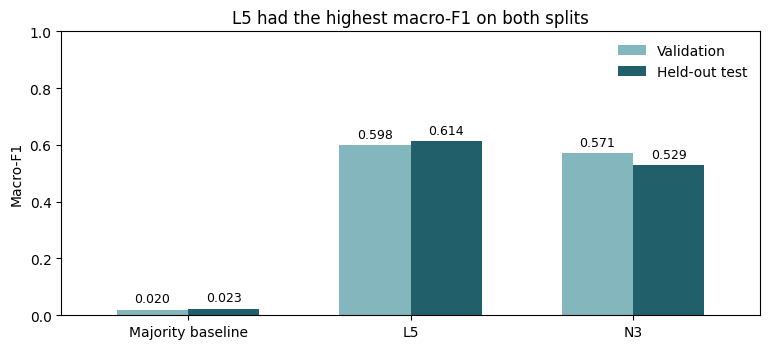

In [26]:
ax = comparison[["validation macro-F1", "test macro-F1"]].plot.bar(
    figsize=(7.8, 3.6), rot=0, color=["#84b6bd", "#215f6b"], width=0.64)
ax.set(title="L5 had the highest macro-F1 on both splits", xlabel="", ylabel="Macro-F1", ylim=(0, 1))
ax.legend(["Validation", "Held-out test"], frameon=False)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.figure.tight_layout()
plt.show()

### Where did L5 make mistakes?

Each row shows one recorded body-part label. Reading across a row shows how L5 labeled those exercises. The numbers are exercise counts, and the color shows the share of the row. Correct predictions fall on the diagonal. For example, the *quadriceps* row shows which other labels L5 assigned to quadriceps exercises.

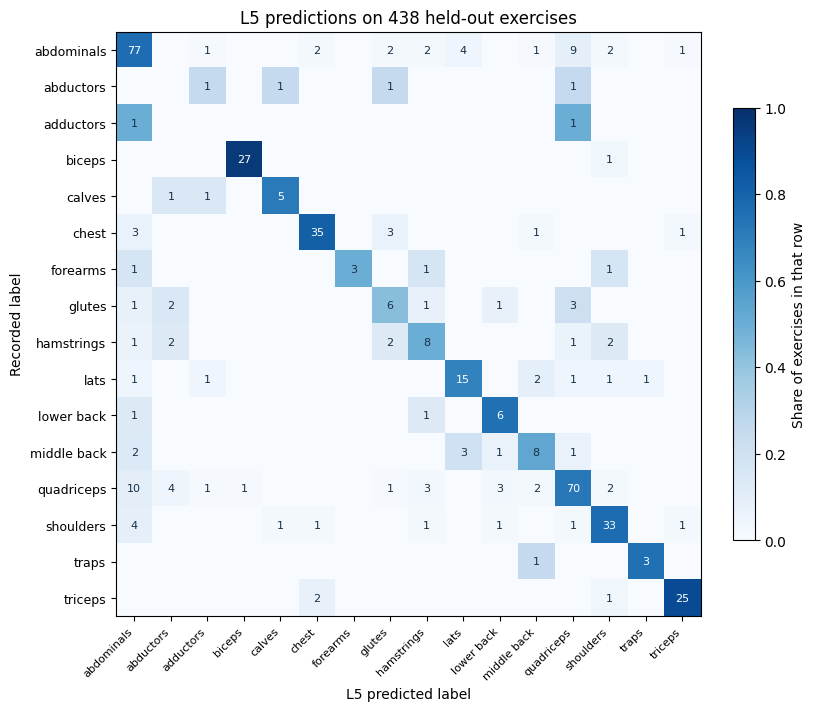

In [27]:
l5_counts = matrices["test", "L5"]
row_shares = l5_counts.div(l5_counts.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(8.3, 7), layout="constrained")
heatmap = ax.imshow(row_shares, cmap="Blues", vmin=0, vmax=1)
positions = range(len(label_order))
ax.set_xticks(positions, label_order, rotation=45, ha="right", fontsize=8)
ax.set_yticks(positions, label_order, fontsize=9)
ax.set(xlabel="L5 predicted label", ylabel="Recorded label", title="L5 predictions on 438 held-out exercises")
for i in positions:
    for j in positions:
        count = l5_counts.iat[i, j]
        if count:
            ink = "white" if row_shares.iat[i, j] > 0.55 else "#183047"
            ax.text(j, i, str(count), ha="center", va="center", color=ink, fontsize=8)
fig.colorbar(heatmap, ax=ax, shrink=0.74, label="Share of exercises in that row")
plt.show()

The first example below is the first saved test exercise that only L5 labeled correctly. The second is the first where both learned models made the same mistake. These examples show how the predictions can differ for an individual exercise. The scores above include all 438.

In [28]:
actual = test_saved["target_label"]
l5_only = test_saved["L5"].eq(actual) & test_saved["N3"].ne(actual) & test_saved["Majority baseline"].ne(actual)
shared_error = test_saved["L5"].eq(test_saved["N3"]) & test_saved["L5"].ne(actual)
example_columns = ["target_label", "Majority baseline", "L5", "N3"]
example_rows = pd.DataFrame({
    "Only L5 correct": test_saved.loc[l5_only, example_columns].iloc[0],
    "Both learned models missed": test_saved.loc[shared_error, example_columns].iloc[0],
}).T.rename(columns={"target_label": "Recorded label"})
display(example_rows)

,Recorded label,Majority baseline,L5,N3
Only L5 correct,chest,abdominals,chest,triceps
Both learned models missed,abdominals,abdominals,lats,lats


### Results and observations

- **Held-out performance.** L5 matched **321 of 438** recorded labels (73.29%), N3 matched **297** (67.81%), and the majority baseline matched **101** (23.06%). L5 got 24 more exercises right than N3, a difference of 5.48 percentage points in accuracy.
- **Which labels were difficult?** L5 recognized **27 of 28 biceps** exercises, but missed **all four abductors** and **both adductors** exercises. With so few examples, even one correct prediction would change recall substantially. The largest mix-up was between quadriceps and abdominals. L5 labeled ten quadriceps exercises as abdominals and nine abdominals exercises as quadriceps.
- **Uncertainty.** Our saved bootstrap analysis resampled the 385 test groups 2,000 times, keeping related exercises together. L5's lead over N3 in macro-F1 was 0.085, with a 95% interval of 0.037 to 0.133. The interval reflects variation across these test groups while holding the trained models fixed. The saved intervals are in `results/statistical_analysis/analysis_d5e368e9f92725a9d389/bootstrap_intervals.csv`.
- **What the labels tell us.** For **236 test exercises**, only the exercise name was available as model input. One source label also leaves out some information when an exercise works several muscles. We explored the full source before we froze the benchmark. Our scores describe agreement with the recorded labels on this split.

## Step 7 — Reference retrieval and planning resources

**Purpose.** Before asking the planner to write a week of basketball practice, we needed to decide what information it should see. We follow one fictional athlete's request from the search results to the references, recovery guidance, and food facts that reached the planner.

**Input.** The 11 indexed passages, fictional development profile, and food records come from `data/unified/v1`. The search vectors and scores are in `artifacts/retrieval/`. The saved reference packet records what the reference-supported planner (V2) received.

**Method.** We used **all-MiniLM-L6-v2**, a pretrained text encoder, with its published weights. It represented each passage and query as a vector of 384 numbers. We ranked up to five passages per query by cosine similarity, which measures how closely two vectors point in the same direction. We encoded the short passage text and kept its source and usage notes to send along if it was selected. The code below reads the saved vectors. In Step 8, **llama3.1:8b** uses the assembled inputs to draft a plan.

In [29]:
import numpy as np

def read_saved_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

retrieval_dir = project_root / "artifacts/retrieval"
index_dir = retrieval_dir / "expanded/expanded_ee12915cfac22530"
index_info = read_saved_json(index_dir / "expanded_manifest.json")
indexed = list(reader["iter_records"](retrieval_use="indexed_reference", decode_data=True))
indexed.sort(key=lambda row: row["data_json"]["metadata_record"]["index_row"])
unit_ids = [row["data_json"]["reference_unit_id"] for row in indexed]
assert unit_ids == index_info["ordered_reference_unit_ids"] and len(unit_ids) == len(set(unit_ids))
titles = {unit: row["title"] for unit, row in zip(unit_ids, indexed)}

passage_vectors = np.load(index_dir / "semantic_embeddings.npy", allow_pickle=False).astype(float)
assert passage_vectors.shape == (len(indexed), index_info["semantic_dimension"])
print(f"Frozen index: {len(indexed)} passages × {passage_vectors.shape[1]} numbers per passage.")
source_names = {"UGA-PEDB-BASKETBALL-TEXTBOOK": "UGA basketball textbook",
                "CDC-YOUTH-PHYSICAL-ACTIVITY": "CDC youth physical activity", "CDC-SLEEP-ABOUT": "CDC sleep"}
source_ids = [row["data_json"]["metadata_record"]["source_family_id"] for row in indexed]
display(pd.Series([source_names[s] for s in source_ids], name="Source").value_counts()
        .rename("Indexed passages").to_frame())

Frozen index: 11 passages × 384 numbers per passage.


,Indexed passages
Source,
UGA basketball textbook,6
CDC youth physical activity,4
CDC sleep,1


### A request for two extra basketball sessions

We use the first profile in the saved V2 development run. The workflow built two short search queries from the information available to the planner. One described the athlete's basketball goals and resources. The other described age, grade, commitments, and recovery. Here is the original request.

In [30]:
v2_summary = read_saved_json(results_dir / "step26_planner_v2_summary.json")
case = v2_summary["reference_packets"][0]
draft = next(reader["iter_records"](record_id="development_profile:" + case["profile_id"], decode_data=True))
request = draft["data_json"]["source_record"]["input"]
packet_path = project_root / case["path"]
packet = read_saved_json(packet_path)
trace = read_saved_json(packet_path.with_suffix(".preparation.json"))
assert case["packet_id"] == packet["packet_id"] == trace["packet_id"]
print(f"Fictional development athlete, age {request['age']}, grade {request['school_grade']}")
print(request["athlete_request"])
print(request["food_question"])

Fictional development athlete, age 13, grade 8
Please plan two extra basketball sessions this week to work on changes of direction. Use only the availability and resources I have listed.
For the food "Strawberries, raw", how many grams of protein are recorded for 100 g?


### Reproduce the rankings from the saved vectors

For each query, we calculate its cosine similarity to all 11 passages, sort the results, and check the top five IDs and scores against the saved ranking. Each indexed passage has its own reference ID. The score gives us an order for that query. We still need to read the source to see which part of the request it addresses.

In [31]:
query_dir = project_root / trace["query_batch_directory"]
report_path, = query_dir.glob("query_report_*.json")
query_report = read_saved_json(report_path)
vector_name = report_path.name.replace("query_report_", "query_vectors_").replace(".json", ".npy")
query_vectors = np.load(query_dir / vector_name, allow_pickle=False).astype(float)
vectors_by_id = {item["query_id"]: vector for item, vector in zip(query_report["query_bindings"], query_vectors)}
passage_lengths = np.linalg.norm(passage_vectors, axis=1)
top_five = pd.DataFrame(index=pd.Index(range(1, 6), name="Rank"))

for topic, saved in zip(["Basketball practice", "Participation and recovery"], trace["ranked_results"]):
    vector = vectors_by_id[saved["query_id"]]
    scores = (passage_vectors @ vector) / (passage_lengths * np.linalg.norm(vector))
    best = np.argsort(-scores, kind="stable")[:5]
    original = saved["result"]["results"]
    assert [unit_ids[i] for i in best] == [item["reference_unit_id"] for item in original]
    np.testing.assert_allclose(scores[best], [item["score"] for item in original], rtol=0, atol=1e-7)
    top_five[topic] = [titles[unit_ids[i]] for i in best]
    top_five[topic + " score"] = scores[best].round(4)
display(top_five)

,Basketball practice,Basketball practice score,Participation and recovery,Participation and recovery score
Rank,,,,
1,Off-ball spacing and team context,0.4862,Youth daily activity and weekly activity mix,0.6029
2,Balance and shooting-hand roles,0.4487,Youth activity intensity and the talk test,0.5217
3,Passing options and outlet context,0.4300,Balance and shooting-hand roles,0.4848
4,Controlled dribbling and court awareness,0.4027,Off-ball spacing and team context,0.4627
5,"Man-to-man, help-side and zone responsibilities",0.3708,Passing options and outlet context,0.4578


### Which references reached the planner?

We took turns selecting from the two ranked lists and kept each passage once. The packet had a **2,200-token** limit for references, rules, and requested food facts. We kept a record of items that could not fit in full.

The first basketball result, *Off-ball spacing and team context*, explains how teammates move in relation to the ball and the defense. It gives the planner material on spacing, but little direction on the athlete's specific request for change-of-direction practice. [UGA basketball chapter](https://open.online.uga.edu/basketball/chapter/4-fundamentals-spacing-rebounding/)

In [32]:
contents = packet["payload"]
preparation = packet["preparation"]
for reference in contents["references"]:
    source_row = indexed[unit_ids.index(reference["reference_unit_id"])]
    whole_text = source_row["data_json"]["delivery_record"]["required_delivery_record"]["display_text"]
    assert reference["complete_required_delivery_text"] == whole_text
    print("Complete passage delivered:", source_row["title"])

sleep = next(rule for rule in contents["planning_rules"]["rules"] if rule["candidate_rule_id"] == "CDC_TEENS_SLEEP")
lo, hi = sleep["reviewed_threshold"]
print(f"Structured rule: {sleep['display_name']}, {lo}–{hi} hours per 24 hours ({sleep['reviewed_enforcement']}).")
print(f"Rule checks executed: {preparation['rule_checks_executed']}.  Delivered drill records: {len(contents['catalog_records'])}.")
print(f"Packet used {preparation['packet_text_tokens']:,} of {preparation['max_packet_tokens']:,} tokens.")
display(pd.Series([entry["kind"] for entry in trace["omissions"]], name="Item").value_counts()
        .rename("Whole items omitted").to_frame())

Complete passage delivered: Off-ball spacing and team context
Structured rule: Daily sleep guidance — ages 13–17, 8–10 hours per 24 hours (advisory).
Rule checks executed: False.  Delivered drill records: 0.
Packet used 2,074 of 2,200 tokens.


,Whole items omitted
Item,
rule,10
reference,6


**Recovery.** A separate lookup used the athlete's age and grade to find the CDC sleep rule. The rule records an advisory range of 8–10 hours per 24 hours for ages 13–17. A weekly average would leave us unable to check individual days. [CDC sleep guidance](https://www.cdc.gov/sleep/about/)

**Food.** The athlete asked how much protein is in **100 g of raw strawberries**. We matched the food and nutrient IDs in the packet to their USDA SR Legacy records in Unified. For a different portion, we multiply each available amount per 100 g by `requested grams / 100`. We leave missing values blank. [USDA record for raw strawberries](https://fdc.nal.usda.gov/food-details/167762/nutrients)

In [33]:
food = contents["food_lookup"][0]["data"]
prepared_foods = list(reader["iter_records"](food_lookup_use="prepared_selected_reference_activation_unverified",
                                            decode_data=True))
food_row = next(row for row in prepared_foods if row["source_record_id"] == food["food_id"])
amounts = pd.DataFrame(food_row["data_json"]["prepared_lookup_nutrients"]).set_index("nutrient_id")
facts = pd.DataFrame(food["nutrients"]).set_index("nutrient_id")
assert set(facts.index) == set(amounts.index)
source_amounts = pd.to_numeric(amounts.loc[facts.index, "amount_per_100g_raw"])
np.testing.assert_allclose(pd.to_numeric(facts["amount"]), source_amounts * float(food["grams"]) / 100)
assert facts["unit"].eq(amounts.loc[facts.index, "unit_name"]).all()
print(f"Saved lookup: {food['description']}, {food['grams']} g, USDA ID {food['food_id']}.")
food_table = facts[["nutrient_name", "amount", "unit"]].copy()
food_table.columns = ["Nutrient", "Amount in the requested portion", "Unit"]
food_table["Unit"] = food_table["Unit"].replace({"KCAL": "kcal", "G": "g"})
display(food_table.set_index("Nutrient"))

missing_nutrients = [(row["title"], n["nutrient_name"]) for row in prepared_foods
                     for n in row["data_json"]["prepared_lookup_nutrients"] if n["amount_per_100g_raw"] in ("", None)]
for name, nutrient in missing_nutrients:
    print(f"Unavailable in the prepared lookup: {nutrient} for {name}.")

Saved lookup: Strawberries, raw, 100 g, USDA ID 167762.
Unavailable in the prepared lookup: Fiber, total dietary for Tempeh.
Unavailable in the prepared lookup: Fiber, total dietary for Crustaceans, shrimp, cooked.


,Amount in the requested portion,Unit
Nutrient,,
Energy,32,kcal
Protein,0.67,g
Total lipid (fat),0.3,g
"Carbohydrate, by difference",7.68,g
"Fiber, total dietary",2,g


### Where the basketball drills came from

We adopted 136 drill variants (127 basketball drills and nine warm-ups) and 29 rule definitions. We held back seven drills and five rules. The Unified release still lists drill activation and the rule validator as pending. It lists 100 USDA SR Legacy foods as ready for lookup. The strawberry example shows one that was used.

The 11 indexed passages contained no drill IDs. The first six V2 development packets therefore supplied no drills. For the final comparison we added a separate step that selected approved drills. V2, V3, and V4 each received one drill in the same 164 cases and none in the other 36. For example, case C001 received the *Pass Fake Breakdown Drill* (`JR-NEW-0045`).

### How well did the search rank references?

We tested two ways to match questions to the same passages. TF-IDF scores shared words, while MiniLM compares the directions of learned text vectors. We compared their top five results on development questions using three measures.

| Measure | Question it answers |
|---|---|
| Recall@5 | What share of the labeled relevant passages appeared in the first five results? |
| MRR@5 | How early did the first relevant passage appear? First place scores 1, second place scores 1/2, and a miss scores 0. We average the scores across questions. |
| Coverage@5 | For what share of supported questions did the top five contain all the required evidence? |

Both methods found all the labeled relevant passages in their top five on development. MiniLM placed the first relevant passage higher on average (MRR@5 of 1.0000 versus 0.9375), so we selected it for the held-out evaluation.

In [34]:
dev_dir = retrieval_dir / "development/comparison_8a912950decb6f7c"
eval_dir = retrieval_dir / "evaluation/evaluation_62d4b123570c2ca8"
metric_files = [dev_dir / "development_route_metrics.csv", eval_dir / "heldout_route_metrics.csv"]
ranking_summary = pd.concat([pd.read_csv(path) for path in metric_files], ignore_index=True)
metric_cols = {"split": "Split", "route": "Search", "completed_outcomes": "Completed",
               "ranking_scored_denominator": "Ranking n", "mean_recall_at_5": "Recall@5", "mrr_at_5": "MRR@5",
               "complete_evidence_scored_denominator": "Coverage n",
               "complete_evidence_set_coverage_rate_at_5": "Coverage@5"}
display(ranking_summary[list(metric_cols)].rename(columns=metric_cols).set_index(["Split", "Search"]).round(4))

held_queries = pd.read_json(eval_dir / "heldout_per_query_metrics.jsonl", lines=True)
print(f"Held-out questions: {len(held_queries)} in {held_queries['question_family_id'].nunique()} families.")
print(held_queries["support_status"].value_counts().rename("Questions").to_string())
print(f"Five candidates returned: {held_queries['returned_unit_count'].eq(5).sum()} of {len(held_queries)}.")

Held-out questions: 30 in 15 families.
support_status
supported              20
unsupported             8
partially_supported     2
Five candidates returned: 30 of 30.


Completed  Ranking n  Recall@5   MRR@5  Coverage n  \
Split       Search                                                         
development lexical          30         24       1.0  0.9375          20   
            semantic         30         24       1.0  1.0000          20   
held_out    semantic         30         24       1.0  0.9792          20   

                      Coverage@5  
Split       Search                
development lexical          1.0  
            semantic         1.0  
held_out    semantic         1.0

### Results and observations

- **What the planner saw.** The saved V2 packet contained one UGA basketball passage, one CDC sleep rule, and one USDA food lookup. It gave the planner the answer to the athlete's food question, **0.67 g of protein in 100 g of strawberries**. The top-ranked participation passage did not fit.
- **How to read the scores.** All 30 held-out questions returned five candidates, including eight questions marked unsupported. Six questions had no labeled relevant passage. Recall@5 (**1.0000**) and MRR@5 (**0.9792**) use the 24 questions with a labeled relevant passage. Coverage@5 (**1.0000**) uses the 20 supported questions, each of which required one passage.
- **Limits.** We scored the search against the benchmark’s saved relevance labels. We had no independent team ratings for those labels. The search results tell us how MiniLM ranked these 11 passages. They leave open whether a planner will use a passage correctly or recognize an unsupported request.
- **Use in the study.** V1 received only the athlete input and planning instructions. V2, V3, and V4 received the same reference packet for a given case. Step 8 follows one saved packet into the calendar the model actually returned.

## Step 8 — AI plan generation

**Purpose.** Can a planner turn a fictional athlete’s request into a seven-day basketball calendar? We follow the V2 development example from Step 7 and compare the athlete’s request with the calendar the model actually wrote.

**Input.** We use the athlete profile and reference packet from Step 7. The saved request, original reply, and format checks are in `results/integration/model_calls/`. The calendar below comes from that saved reply.

### One language model, four ways to plan

All four workflows used the same local language model, **`llama3.1:8b`**, to write a response. We changed what it could read and how many times it could work on a draft. The exercise classifier (L5) had already served its purpose in catalog tagging. MiniLM ranked the references used in the reference packet.

| Workflow | How we produced the response |
|---|---|
| V1 · Direct | The model read the athlete’s request and our planning instructions, then wrote one reply. |
| V2 · Reference-supported | We also gave the model a packet of references matched to the athlete. It wrote one reply. |
| V3 · Specialists and coordinator | We gave the same model separate training and recovery roles, plus a food role when the athlete asked a food question. A final coordinator call used the original inputs and the specialist notes to write the reply. |
| V4 · Checked draft and revisions | V4 built its own draft using specialist notes. We checked the draft in code and asked the model to evaluate it. The coordinator could revise it up to twice, with checks after each revision. |

Step 9 compares all four workflows on the same athletes. Step 10 shows a separate application demonstration.

### What did V2 receive?

We match the athlete and reference packet to their saved V2 request. The system message gave the planning instructions. The user message contained the athlete’s details and reference packet. We check that both match the inputs we read in Step 7.

In [35]:
model_config = read_saved_json(project_root / "artifacts/language_model/integration_config.json")
public_profile = draft["data_json"]["source_record"]
dev_log = (results_dir / "planner_v2/development_runs.jsonl").read_text(encoding="utf-8").splitlines()
v2_run = next(
    row for row in map(json.loads, dev_log)
    if row["profile_id"] == public_profile["profile_id"]
    and row["reference_packet_id"] == packet["packet_id"]
)
calls_dir = results_dir / "integration/model_calls"
call_dir = calls_dir / v2_run["result"]["call_id"]
wire = read_saved_json(call_dir / "request.json")["request"]
system_message, user_message = wire["messages"]
assert [system_message["role"], user_message["role"]] == ["system", "user"]
assert json.loads(user_message["content"]) == {"athlete_input": request, "reference_data": packet["payload"]}
assert (wire["model"], wire["options"]) == (model_config["model"], model_config["options"])

print("System message, opening line:", system_message["content"].splitlines()[0])
print("Fictional athlete:", request["athlete_request"])
print("Food question:", request["food_question"])
print("Available windows:", ", ".join(f"{w['date']} {w['start_time']}–{w['end_time']}" for w in request["availability"]))
print("Existing commitments listed:", len(request["existing_commitments"]))
print("Reference inputs:", len(contents["references"]), "passage,", len(contents["planning_rules"]["rules"]), "rule,",
      len(contents["food_lookup"]), "food lookup.")
print("Model:", wire["model"], "| Quantization:", model_config["quantization"], "| Saved options:", wire["options"])

System message, opening line: We help teenage athletes organize a week of basketball practice around their supplied goals and circumstances.
Fictional athlete: Please plan two extra basketball sessions this week to work on changes of direction. Use only the availability and resources I have listed.
Food question: For the food "Strawberries, raw", how many grams of protein are recorded for 100 g?
Available windows: 2026-11-16 17:30–17:50, 2026-11-18 17:30–17:50, 2026-11-21 17:30–17:50
Existing commitments listed: 0
Reference inputs: 1 passage, 1 rule, 1 food lookup.
Model: llama3.1:8b | Quantization: Q4_K_M | Saved options: {'temperature': 0, 'seed': 42, 'num_ctx': 8192, 'num_predict': 2048}


### How did V2 generate a reply?

Our V2 planner called `RAGPlanner(project_root).generate(public_profile, packet, call_id)`. It checked which model was installed, assembled the prompt, checked that it fit, and sent one request to the local Ollama service at `/api/chat`. We used temperature 0, seed 42, an 8,192-token context window, and a limit of 2,048 output tokens.

We allowed the model to return a **plan**, ask for **clarification** when essential information was missing, report a **constraint conflict** when the requirements could not all be met, or flag a request as **outside scope**. Here we read the original reply and check that it matches the version saved by the planner. The explanation printed below is the model’s own account of its calendar.

In [36]:
recorded = read_saved_json(call_dir / "result.json")
backend = read_saved_json(call_dir / "backend_response.json")
original_text = backend["message"]["content"]
saved_plan = json.loads(original_text)
parsed = recorded["response"]["model_output"]
assert original_text == parsed["raw_text"] and saved_plan == parsed["parsed_object"]
assert saved_plan == v2_run["result"]["response"]["model_output"]["parsed_object"]
print("SAVED V2 DEVELOPMENT RESPONSE")
print("Response type:", saved_plan["response_type"], "| Backend stop reason:", backend["done_reason"])
print("Passed completion check:", recorded["completion_valid"], "| Passed format check:", recorded["format_valid"])
print("Generation submissions:", v2_run["result"]["transport_attempts"]["generation"],
      "| Input tokens:", backend["prompt_eval_count"], "| Output tokens:", backend["eval_count"])
print("Model's explanation:", saved_plan["explanation"])

SAVED V2 DEVELOPMENT RESPONSE
Response type: plan | Backend stop reason: stop
Passed completion check: True | Passed format check: True
Generation submissions: 1 | Input tokens: 3633 | Output tokens: 786
Model's explanation: Two extra basketball sessions have been added to the athlete's schedule to work on changes of direction.


### What did the saved calendar include?

Each row shows the local time, description, and rest guidance from the original reply. On days without an activity, the table shows the model’s rest entry. The athlete listed no existing commitments, so every scheduled session was an addition.

In [37]:
def calendar_frame(answer):
    entries = []
    for day in answer["weekly_schedule"]:
        for activity in day["activities"] or [None]:
            entry = {
                "Date": day["date"],
                "Day": pd.Timestamp(day["date"]).day_name()[:3],
                "Start": "",
                "End": "",
                "Minutes": None,
                "Activity as returned": "—",
                "Rest as returned": day["rest_arrangements"],
            }
            if activity:
                timing = activity.get("timing") or {}
                entry.update({
                    "Start": timing.get("start_time"),
                    "End": timing.get("end_time"),
                    "Minutes": activity["duration_minutes"],
                    "Activity as returned": activity["description"],
                })
            entries.append(entry)
    table = pd.DataFrame(entries)
    table["Minutes"] = table["Minutes"].astype("Int64").astype("string").fillna("")
    return table.set_index(["Date", "Day"])

print("Saved V2 calendar ·", saved_plan["planning_window"]["timezone"])
with pd.option_context("display.max_colwidth", None):
    display(calendar_frame(saved_plan))

Saved V2 calendar · America/Los_Angeles


,,Start,End,Minutes,Activity as returned,Rest as returned
Date,Day,,,,,
2026-11-16,Mon,17:30,17:50,20,Basketball session to work on changes of direction,Rest after the session
2026-11-17,Tue,,,,—,Rest day
2026-11-18,Wed,17:30,17:50,20,Basketball session to work on changes of direction,Rest after the session
2026-11-19,Thu,,,,—,Rest day
2026-11-20,Fri,,,,—,Rest day
2026-11-21,Sat,17:30,17:50,20,Basketball session to work on changes of direction,Rest after the session
2026-11-22,Sun,,,,—,Rest day


### Did V2 do what the athlete asked?

The athlete asked for **two extra sessions**. Their profile allowed up to **three sessions and 60 minutes** that week. We count the sessions in the calendar, check whether each one fits an available window, and look for an answer to the athlete’s question about protein in strawberries.

In [38]:
added = []
for day in saved_plan["weekly_schedule"]:
    for activity in day["activities"]:
        if not activity["existing_commitment_refs"] and activity["relationship"]["kind"] == "separate_session":
            added.append((day["date"], activity))

within_windows = 0
for session_date, activity in added:
    timing = activity["timing"]
    fits = any(
        window["date"] == session_date
        and window["start_time"] <= timing["start_time"] < timing["end_time"] <= window["end_time"]
        for window in request["availability"]
    )
    within_windows += int(fits)

limits = request["time_limits"]
assert "two extra basketball sessions" in request["athlete_request"].lower()
minutes = sum(activity["duration_minutes"] for _, activity in added)
print(f"Requested sessions: 2. Calendar sessions: {len(added)}. Profile ceiling: {limits['max_additional_sessions_per_week']}.")
print(f"Scheduled minutes: {minutes}. Weekly ceiling: {limits['max_additional_minutes_per_week']}.")
print(f"Sessions inside an offered window: {within_windows} of {len(added)}.")
print("Food facts returned:", len(saved_plan.get("food_facts") or []))
dev_scores = pd.read_csv(results_dir / "planner_v2/development_scores.csv").set_index("profile_id")
quality = dev_scores.loc[public_profile["profile_id"], "plan_quality_score"]
print("Saved development quality score:", "unscored" if pd.isna(quality) else quality)

Requested sessions: 2. Calendar sessions: 3. Profile ceiling: 3.
Scheduled minutes: 60. Weekly ceiling: 60.
Sessions inside an offered window: 3 of 3.
Food facts returned: 0
Saved development quality score: unscored


### Earlier calendar checks

Before we compared the four workflows, we asked the model to copy two existing practices into a calendar with their original dates and times. We kept all seven attempts. A blank in the last column means the project has no separate calendar-check file for that attempt.

In [39]:
history_rows = []
for number in range(1, 8):
    folder = calls_dir / f"step24_12_calendar_example_{number:02d}"
    attempt = read_saved_json(folder / "result.json")
    check_path = folder / "calendar_check.json"
    calendar_result = ""
    if check_path.is_file():
        check = read_saved_json(check_path)
        calendar_result = "Passed" if check["calendar_fulfilled"] else "Failed"
    history_rows.append({
        "Attempt": f"{number:02d}",
        "Response type": attempt["response_type"] or "Unparsed",
        "Complete": attempt["completion_valid"],
        "Valid format": attempt["format_valid"],
        "Calendar fulfilled": calendar_result,
    })
display(pd.DataFrame(history_rows).set_index("Attempt"))

,Response type,Complete,Valid format,Calendar fulfilled
Attempt,,,,
01,plan,True,False,
02,plan,True,False,
03,plan,True,False,
04,outside_scope,True,True,
05,Unparsed,False,False,Failed
06,plan,True,True,Failed
07,plan,True,True,Passed


Attempts **01–03** failed the format checks on rest fields, commitment references, or the parent activity ID. Attempt **04** treated this in-scope request as outside scope. Attempt **05** stopped before the JSON was complete. Attempt **06** produced a calendar and left out both end times. On attempt **07**, the calendar showed both practices from **17:00 to 18:00 on November 17 and 19**, with no added sessions. It passed all 11 checks for that task.

### Optional · Generate one V2 reply locally

The calendar above is saved in the notebook. For a separate local example, we start the project’s pinned Ollama runtime with the matching model installed, then set the switch below to `True`. The planner saves the result in `results/integration/model_calls/` under its own notebook-example ID. Once that result exists, running the cell again opens the saved example. It is separate from the four-planner study.

In [40]:
RUN_ONE_NEW_V2_RESPONSE = False

if RUN_ONE_NEW_V2_RESPONSE:
    from champion_athletic_map.planners.rag import RAGPlanner

    demo_id = "notebook_step8_v2_" + recorded["request_sha256"][:16]
    demo = RAGPlanner(project_root).generate(public_profile, packet, demo_id)
    label = "Previously saved optional V2 result" if demo.get("cached") else "New optional V2 attempt"
    print(label, "·", demo["status"], "·", demo_id)
    if demo.get("response") and demo.get("format_valid") and demo.get("completion_valid"):
        demo_answer = demo["response"]["model_output"]["parsed_object"]
        print("Response type:", demo_answer["response_type"])
        if demo_answer["response_type"] == "plan":
            print(demo_answer["explanation"])
            with pd.option_context("display.max_colwidth", None):
                display(calendar_frame(demo_answer))
            if demo_answer.get("food_facts"):
                print(json.dumps(demo_answer["food_facts"], indent=2, ensure_ascii=False))
        else:
            print(json.dumps(demo_answer, indent=2, ensure_ascii=False))
    else:
        print(demo.get("error") or "The adapter did not record a complete, format-valid response.")
else:
    print("Saved examples only. Optional local generation is off.")

Saved examples only. Optional local generation is off.


### Results and observations

V2 said it added **two sessions**. We counted **three**. It used every available 20-minute window and stayed within the 60-minute weekly limit, but the athlete had asked for only two sessions. Each entry repeated “Basketball session to work on changes of direction.” None named a drill or explained how to practice it.

The model also left the food question unanswered. Its reference packet gave the value the athlete needed, **0.67 g of protein per 100 g of raw strawberries**. These observations come from comparing one saved reply with its inputs. The development record has no overall quality score for this case.

## Step 9 — Four-planner evaluation and comparison

**Purpose.** Which workflow handled the athletes’ requests most reliably, and how much time did each take? We compare V1 (direct), V2 (with references), V3 (specialists and coordinator), and V4 (checked draft with revisions). All four used `llama3.1:8b`.

**Input and method.** We use the saved final-study outcomes and the original statistical analysis. Each of the 200 fictional athletes gave the same request to all four workflows, for **800 outcomes**. We count one final outcome per athlete and workflow, including failed jobs. A revision belongs to the job that produced it. The calendars in this section come from those saved outcomes.

### Which requests did we test?

In [41]:
study = read_saved_json(results_dir / "step33_saved_results_comparison_summary.json")
analysis_note = read_saved_json(results_dir / "step35_statistical_analysis_summary.json")
study_dir = (project_root / analysis_note["findings_path"]).parent
jobs = pd.read_csv(study_dir / "failure_analysis.csv")
per_case = jobs.groupby(["profile_id", "planner"]).size().unstack(fill_value=0)
assert per_case.columns.tolist() == [1, 2, 3, 4] and per_case.eq(1).all().all()
assert jobs["job_id"].is_unique and jobs.groupby("profile_id")["case_category"].nunique().eq(1).all()
assert len(per_case) == study["cases_verified"] and len(jobs) == study["outcomes_verified"]

case_labels = {"feasible": "Feasible request", "missing_information": "Missing essential information",
               "conflicting_constraints": "Conflicting constraints", "outside_scope": "Outside scope"}
categories = jobs.drop_duplicates("profile_id")["case_category"].value_counts().reindex(case_labels)
print(f"{len(per_case)} fictional profiles × {len(per_case.columns)} planners = {len(jobs)} designated outcomes.")
display(categories.rename(index=case_labels).rename_axis("Case type").rename("Profiles per planner").to_frame())

200 fictional profiles × 4 planners = 800 designated outcomes.


,Profiles per planner
Case type,
Feasible request,150
Missing essential information,20
Conflicting constraints,15
Outside scope,15


### What counted as a success?

We used all **200 requests per planner** for the first two measures. **Workflow completed** means the workflow reached a recorded endpoint. For V4, that could mean reaching the revision limit with a draft it had never accepted. **Valid format** means the reply followed the required structure.

The last three measures use the **150 feasible requests per planner**. A **valid completed plan** is a completed, correctly formatted reply that identifies itself as a plan. **Coded checks passed** means all required checks implemented in code passed, including the checks on supporting resources. **Full verification** also requires evidence that the plan met the athlete’s complete request, including the skill goal. An unresolved required check prevents a pass.

In [42]:
metric_rows = pd.read_csv(study_dir / "planner_summary.csv")
measures = {"designated_workflow_completed": "Workflow completed", "strict_format_valid": "Valid format",
            "completed_valid_plan": "Valid completed plan", "automated_declared_checks_pass": "Coded checks passed",
            "complete_request_fulfillment_verified": "Full verification"}
main_scores = metric_rows.loc[metric_rows["metric"].isin(measures)].copy()
assert main_scores.set_index(["planner", "metric"]).index.is_unique
for version, group in jobs.groupby("planner"):
    saved = main_scores.loc[main_scores["planner"].eq(version)].set_index("metric")
    assert group["workflow_completed"].sum() == saved.loc["designated_workflow_completed", "numerator"]
    assert group["strict_format_valid"].sum() == saved.loc["strict_format_valid", "numerator"]
    feasible = study["comparison"]["planners"][str(version)]["feasible"]
    assert saved.loc["completed_valid_plan", "numerator"] == feasible["completed_valid_plan_responses"]

def counts_by_planner(rows, field, labels):
    counts = rows.assign(count=rows["numerator"].astype(str) + " / " + rows["denominator"].astype(str))
    table = counts.pivot(index="planner", columns=field, values="count")
    table = table.loc[:, list(labels)].rename(columns=labels).rename_axis(columns=None)
    return table.rename(index=lambda n: f"V{n}").rename_axis("Planner")

display(counts_by_planner(main_scores, "metric", measures))

paired_format = jobs.pivot(index="profile_id", columns="planner", values="strict_format_valid")
print(f"On the same 200 profiles, {(paired_format[1] & ~paired_format[2]).sum()} passed format only in V1 "
      f"and {(paired_format[2] & ~paired_format[1]).sum()} passed format only in V2 when comparing those two workflows.")

On the same 200 profiles, 33 passed format only in V1 and 20 passed format only in V2 when comparing those two workflows.


,Workflow completed,Valid format,Valid completed plan,Coded checks passed,Full verification
Planner,,,,,
V1,199 / 200,75 / 200,45 / 150,0 / 150,0 / 150
V2,186 / 200,62 / 200,40 / 150,0 / 150,0 / 150
V3,199 / 200,67 / 200,39 / 150,0 / 150,0 / 150
V4,198 / 200,69 / 200,47 / 150,0 / 150,0 / 150


V1 had the most correctly formatted replies (**75/200**). V4 had the most completed, correctly formatted plans for feasible requests (**47/150**). Each planner scored **0/150** on both coded checks and full verification. The individual checks below help explain what those zeros mean.

### Which problems could we verify?

In [43]:
checks = pd.read_csv(study_dir / "parent_check_summary.csv")
feasible_checks = checks.loc[checks["population"].eq("feasible")].set_index(["check_id", "planner"])
reasons = pd.DataFrame({
    "Existing commitment violated": feasible_checks.loc["existing_commitments", "violated"],
    "Requested session count violated": feasible_checks.loc["requested_session_count", "violated"],
    "Additional training limit violated": feasible_checks.loc["additional_training_limits", "violated"],
    "Goal fulfillment unknown": feasible_checks.loc["public_goal_fulfillment", "unknown"],
})
print("Number of feasible cases out of 150 per planner. One case can appear in several columns.")
display(reasons.rename(index=lambda n: f"V{n}").rename_axis("Planner"))

Number of feasible cases out of 150 per planner. One case can appear in several columns.


,Existing commitment violated,Requested session count violated,Additional training limit violated,Goal fulfillment unknown
Planner,,,,
V1,28,22,23,150
V2,32,33,25,150
V3,24,26,25,150
V4,28,36,36,150


Our goal check was unfinished, so goal fulfillment was **unknown in all 150 feasible cases for each planner**. The resource checks also recognized only a limited set of activity descriptions. We could still verify specific scheduling mistakes. For example, the checks found that V1 violated an existing commitment in 28 cases and V2 violated the requested session count in 33.

For the remaining **50 requests per planner**, a suitable answer could ask for missing information, identify a conflict, or explain that a request was outside scope. We scored whether the reply handled the specific problem. Choosing the right response label was only one part of that assessment.

In [44]:
challenges = metric_rows.loc[metric_rows["metric"].eq("category_response_success")]
challenge_labels = {key: case_labels[key] for key in ["missing_information", "conflicting_constraints", "outside_scope"]}
display(counts_by_planner(challenges, "population", challenge_labels))

,Missing essential information,Conflicting constraints,Outside scope
Planner,,,
V1,0 / 20,0 / 15,3 / 15
V2,0 / 20,0 / 15,5 / 15
V3,0 / 20,0 / 15,8 / 15
V4,0 / 20,0 / 15,3 / 15


### How much time did each workflow take?

We use the median time from start to finish across all 200 jobs per planner, including failures. We exclude the time spent scoring the replies afterward. The second chart counts every model call used to draft, write specialist notes, evaluate, or revise.

Recorded generation submissions across the study: 2,636.
V4 terminal outcomes: {'revision_limit_reached': 198, 'execution_error': 2}


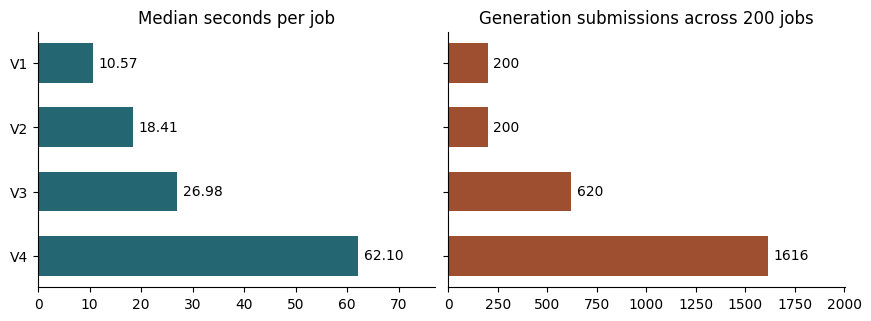

In [45]:
runtime = pd.read_csv(study_dir / "runtime_resource_summary.csv")
all_terminal = runtime.loc[runtime["population"].eq("all_terminal")].set_index("planner").sort_index()
calls = pd.read_csv(study_dir / "native_runtime_by_planner.csv").set_index("planner_version").sort_index()
assert all_terminal["measured"].eq(200).all() and all_terminal["missing"].eq(0).all()
assert calls["generation_submissions"].sum() == study["cumulative_model_submissions"]
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.1), layout="constrained", sharey=True)
for ax, series, title, label_format, color in [
    (axes[0], all_terminal["median_seconds"], "Median seconds per job", "%.2f", "#246671"),
    (axes[1], calls["generation_submissions"], "Generation submissions across 200 jobs", "%.0f", "#9e4f2f"),
]:
    bars = ax.barh([f"V{v}" for v in series.index], series, color=color, height=0.62)
    ax.bar_label(bars, fmt=label_format, padding=4)
    ax.set(xlim=(0, series.max() * 1.24), title=title)
    ax.spines[["right", "top"]].set_visible(False)
axes[0].invert_yaxis()
plt.show()
print(f"Recorded generation submissions across the study: {study['cumulative_model_submissions']:,}.")
print("V4 terminal outcomes:", jobs.loc[jobs["planner"].eq(4), "terminal_state"].value_counts().to_dict())

V1 took **10.57 seconds** at the median. V4 took **62.10 seconds**. Of V4’s 200 jobs, 198 reached the revision limit and two ended in execution errors. V4 never accepted a final response under its own checks.

### Four calendars for one athlete

We chose **C002** because all four workflows returned a readable seven-day plan for that athlete. We compare each one with the existing commitment, available times, and weekly training limit. The tables above include all 200 profiles, including cases where a planner produced no usable calendar.

In [46]:
case_dir = results_dir / "pilot/probes/finalcase_22662ab54985a88d_c002/jobs"
case_files = [read_saved_json(path) for path in case_dir.glob("*/outcome.json")]
case_replies = {record["planner_version"]: record for record in case_files}
assert len(case_files) == 4 and set(case_replies) == {1, 2, 3, 4}
case_input = case_replies[1]["response"]["authoritative_public_input"]
case_id = case_replies[1]["response"]["audit"]["profile_id"]
case_jobs = jobs.loc[jobs["profile_id"].eq(case_id)].set_index("planner")
assert len(case_jobs) == 4 and case_jobs["case_category"].eq("feasible").all()
answers = {}
for version in sorted(case_replies):
    record = case_replies[version]
    assert record["response"]["authoritative_public_input"] == case_input
    assert record["response"]["audit"]["profile_id"] == case_id
    assert case_jobs.loc[version, "strict_format_valid"]
    assert record["format_valid"] and record["completion_valid"] and record["response_type"] == "plan"
    answers[version] = record["response"]["model_output"]["parsed_object"]

print(f"Fictional athlete, age {case_input['age']}, grade {case_input['school_grade']}.")
print(case_input["athlete_request"])
print("Additional-training limits:", case_input["time_limits"])

Fictional athlete, age 17, grade 11.
For the week shown, help me work toward this priority: Manage my pace during short basketball practice blocks. Pick 2 additional practice blocks within my recorded limits.
Additional-training limits: {'max_additional_minutes_per_week': 40, 'max_additional_sessions_per_week': 2, 'max_session_minutes': 20}


In [47]:
dates = pd.date_range(case_input["planning_window"]["start_date"], periods=7).strftime("%Y-%m-%d")
calendar = pd.DataFrame(index=pd.Index(dates, name="Date"))
public_day = {date: [] for date in dates}
for w in case_input["availability"]:
    public_day[w["date"]].append(f"Available {w['start_time']}–{w['end_time']}")
for event in case_input["existing_commitments"]:
    public_day[event["date"]].append(f"{event['description']} {event['start_time']}–{event['end_time']}")
calendar["Public schedule"] = [" + ".join(public_day[date]) or "—" for date in dates]

def activity_time(activity):
    timing = activity.get("timing") or {}
    clock = "Time missing"
    if timing.get("start_time") and timing.get("end_time"):
        clock = f"{timing['start_time']}–{timing['end_time']}"
    return f"{clock} ({activity['duration_minutes']} min)"

activity_summary = []
for version, answer in answers.items():
    days = answer["weekly_schedule"]
    assert [day["date"] for day in days] == list(dates)
    calendar[f"V{version}"] = [" + ".join(activity_time(a) for a in day["activities"]) or "—" for day in days]
    entries = [a for day in days for a in day["activities"]]
    descriptions = dict.fromkeys(a["description"] for a in entries)
    activity_summary.append({"Planner": f"V{version}", "Activity entries": len(entries),
                             "Minutes listed": sum(a["duration_minutes"] for a in entries),
                             "Descriptions used in the reply": " · ".join(descriptions)})
print("Saved calendars in local time. A dash means no listed activity or public time window.")
with pd.option_context("display.max_colwidth", None):
    display(calendar)
    display(pd.DataFrame(activity_summary).set_index("Planner"))

Saved calendars in local time. A dash means no listed activity or public time window.


,Public schedule,V1,V2,V3,V4
Date,,,,,
2026-11-16,Volleyball practice 15:00–16:00,—,—,—,Time missing (15 min)
2026-11-17,—,17:00–17:15 (15 min),17:00–17:15 (15 min),Time missing (10 min) + Time missing (20 min),Time missing (15 min)
2026-11-18,Available 18:20–18:40,18:20–18:35 (15 min),17:20–17:35 (15 min),Time missing (10 min),Time missing (20 min)
2026-11-19,—,—,—,Time missing (20 min),Time missing (15 min)
2026-11-20,Available 18:20–18:40,18:20–18:35 (15 min),17:20–17:35 (15 min),Time missing (10 min),Time missing (15 min)
2026-11-21,—,—,—,—,Time missing (15 min)
2026-11-22,—,—,—,—,Time missing (15 min)


,Activity entries,Minutes listed,Descriptions used in the reply
Planner,,,
V1,3,45,Short basketball practice block to work on pace management
V2,3,45,Short basketball practice block to work on pace management
V3,5,70,Warm-up and stretching · Pace management drills · Cool-down and stretching
V4,7,110,Short basketball practice block · Pace management drills


The athlete already had volleyball on **Monday from 15:00 to 16:00**. All four calendars left it out. The athlete also asked for **two extra blocks, up to 40 minutes total**. V1 and V2 each listed three 15-minute blocks. V1 fit Wednesday and Friday inside the available windows. V2 started both an hour early. V3 listed five activities totaling 70 minutes. V4 listed seven totaling 110 minutes. Neither V3 nor V4 gave start and end times. All four calendars passed the format check. The study recorded violations for existing commitments, requested session counts, and additional-training limits in all four replies.

### Results and observations

- **Planning outcomes.** Each planner scored **0/150** on full verification of feasible requests. All four also scored **0/20** on requests with missing information and **0/15** on conflicting constraints. V3 handled **8/15** outside-scope requests successfully, compared with 3 for V1, 5 for V2, and 3 for V4. V1 was the fastest and produced the most correctly formatted replies. We found no overall winner.
- **Limits of the comparison.** The 150 feasible cases used only three original wording patterns. The paired analysis resampled request families 2,000 times using seed 42. We documented some statistical choices, including how to interpolate percentiles, during analysis. Because every planner scored zero on the primary outcome, the interval for each paired difference was [0, 0]. This tells us little about how the workflows would compare with new requests and a complete goal check.

### What did the supplementary team review add?

The supplementary team review covered 160 replies from 40 fictional profiles after the final results were known. The rubric covered five areas: response suitability, fit to the athlete, practicality and completeness, evidence accuracy, and clarity. The review produced one set of ratings, with 799 numeric scores and one entry marked not applicable. Our original protocol called for two independent sets of teammate ratings. Without those paired scores, we could not measure agreement.

One reply gave **26.52 g of protein for 120 g of salmon**. The saved reference gave 22.1 g per 100 g, and multiplying 22.1 by 1.2 gives 26.52. The team review credited that statement even though the automatic food check left it unverified. We kept the automatic score in the study results. The rating method and the supporting example are recorded in `results/team_review/review_1c8c6d51f99740e019ac/`.

Step 10 shows what happened in a separate live application test with a fictional athlete.

## Step 10 — Fictional-athlete live demonstration and conclusions

**Purpose.** What would a fictional athlete actually see? We follow one request from the athlete's available time and equipment to the proposed calendar. We check which drills the app offered, how it scheduled them, and what its checks could establish.

**Input and method.** CODE-4 was our separate live application. Its workflow, `live-draft-1`, ran the same request twice. We load both saved jobs from `results/app_live/jobs/`, compare their requests and replies, and check the calendar against the resources the app used. The four-planner results in Step 9 cover a different set of 800 outcomes.

**Reading or running the demo.** The saved calendar, recovery guidance, and food example are visible below. To try a different profile, run the Step 10 cells in order from the project root or its `notebooks` folder using the project environment. The preview uses `data/unified/v1` and the app's original functions. Only the optional generation cell needs a running local model.

In [48]:
import hashlib
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

demo_root = Path.cwd()
if demo_root.name == "notebooks":
    demo_root = demo_root.parent
if not (demo_root / "data/unified/v1/dataset_manifest.json").is_file():
    raise FileNotFoundError("Open this notebook from the project root or its notebooks folder.")
for directory in (demo_root / "src", demo_root):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
from app import live_engine, live_resources


def load_demo_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


archive_ids = ["20261117T213113_5d37f818b99f", "20261117T213756_7b14667ffbf8"]
archive_dir = demo_root / "results/app_live/jobs"
historical = [load_demo_json(archive_dir / job / "outcome.json") for job in archive_ids]
job_rows = []
for job, record in zip(archive_ids, historical):
    saved_request = load_demo_json(archive_dir / job / "request.json")
    wire_hash = hashlib.sha256(live_engine._wire(saved_request)).hexdigest()
    assert wire_hash == record["request_sha256"] and record["job_id"] == job
    assert record["workflow"] == "live-draft-1" and record["provenance"]["evaluated_planner"] is False
    backend_reply = load_demo_json(archive_dir / job / "response.json")
    assert json.loads(backend_reply["message"]["content"]) == record["parsed_response"] == record["response"]
    job_rows.append({
        "Saved job": job,
        "Status": record["status"],
        "Sessions": len(record["parsed_response"]["sessions"]),
        "Valid format": record["format_valid"],
        "Schedule checks passed": record["assessment"]["passed"],
    })

assert historical[0]["request_sha256"] == historical[1]["request_sha256"]
assert historical[0]["parsed_response"] == historical[1]["parsed_response"]
print("SAVED CODE-4 APPLICATION RESULTS · two jobs, one request, identical parsed plans")
display(pd.DataFrame(job_rows).set_index("Saved job"))

SAVED CODE-4 APPLICATION RESULTS · two jobs, one request, identical parsed plans


,Status,Sessions,Valid format,Schedule checks passed
Saved job,,,,
20261117T213113_5d37f818b99f,draft_ready,2,True,True
20261117T213756_7b14667ffbf8,draft_ready,2,True,True


### The saved CODE-4 calendar

Our fictional athlete was a 16-year-old beginner who wanted two 15-minute dribbling sessions. The athlete was free on Monday, Wednesday, and Saturday from 17:30 to 18:00, had a basketball and a hoop, and could use a full court alone. The request listed no existing practices. Both runs returned the same plan, so we show the first one. A dash marks a day with no entry.

In [49]:
def show_app_result(record, rules):
    print("Job:", record["job_id"], "| Status:", record["status"])
    if record.get("error"):
        print(record["error"])
    assessment = record.get("assessment") or {}
    for issue in assessment.get("issues", []):
        print("Recorded issue:", issue)
    if not (record.get("completion_valid") and record.get("format_valid")):
        print("This attempt has no complete, format-valid reply to display.")
        return

    reply, profile = record["parsed_response"], record["profile"]
    print("Response type:", reply["response_type"], "|", reply["explanation"])
    for question in reply.get("questions", []):
        print("Question:", question)
    if reply["response_type"] != "plan":
        return

    calendar = {
        day.strftime("%Y-%m-%d"): {"Existing commitments": [], "Proposed sessions": []}
        for day in pd.date_range(profile["week_start"], periods=7)
    }
    by_id = {item["id"]: item for item in record["selected_candidates"]}
    for event in profile["existing_practices"]:
        line = f"{event['start_time']}–{event['end_time']} · {event['description']}"
        calendar[event["date"]]["Existing commitments"].append(line)
    for session in reply["sessions"]:
        name = by_id.get(session["drill_id"], {}).get("name", session["drill_id"])
        line = f"{session['start_time']} · {session['duration_minutes']} min · {name}"
        day = calendar.setdefault(session["date"], {"Existing commitments": [], "Proposed sessions": []})
        day["Proposed sessions"].append(line)
    rows = []
    for day, entries in sorted(calendar.items()):
        rows.append({
            "Date": day,
            "Existing commitments": " / ".join(entries["Existing commitments"]) or "—",
            "Proposed sessions": " / ".join(entries["Proposed sessions"]) or "—",
        })
    print("Calendar time zone:", profile["timezone"])
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame(rows).set_index("Date"))

    rule_urls = {rule["id"]: rule["source_url"] for rule in rules}
    for guidance in reply["recovery_guidance"]:
        print("Recovery guidance:", guidance["statement"])
        for rule_id in guidance["source_rule_ids"]:
            print("Source:", rule_id, rule_urls.get(rule_id, "(no matching source in this request)"))

archived_input = load_demo_json(archive_dir / archive_ids[0] / "input.json")
example = historical[0]
rechecked = live_engine.assess(
    example["profile"],
    example["parsed_response"],
    example["selected_candidates"],
    archived_input["rules"],
)
assert rechecked == example["assessment"]
show_app_result(example, archived_input["rules"])

Job: 20261117T213113_5d37f818b99f | Status: draft_ready
Response type: plan | Generated plan based on provided data
Calendar time zone: America/Los_Angeles
Recovery guidance: Weekly rest from sport-specific training and competition
Source: AAP_WEEKLY_SPORT_REST https://www.healthychildren.org/English/health-issues/injuries-emergencies/sports-injuries/Pages/Too-Much-Too-Soon-Overtraining.aspx


,Existing commitments,Proposed sessions
Date,,
2026-11-16,—,17:30 · 15 min · 5-5-5 Creative Dribble
2026-11-17,—,—
2026-11-18,—,17:30 · 15 min · Rhythm Dribbling
2026-11-19,—,—
2026-11-20,—,—
2026-11-21,—,—
2026-11-22,—,—


The app proposed **5-5-5 Creative Dribble** on Monday and **Rhythm Dribbling** on Wednesday, both from **17:30 to 17:45**. That met the athlete's request for two sessions and left Saturday free. The recovery note cited the American Academy of Pediatrics (AAP) rule in our catalog about weekly rest from sport-specific training and competition. [AAP source used in the demo](https://www.healthychildren.org/English/health-issues/injuries-emergencies/sports-injuries/Pages/Too-Much-Too-Soon-Overtraining.aspx)

**What the calendar leaves out.** The Jr. NBA source lists **one minute** for the first drill and **three minutes** for the second. The draft gave each drill a 15-minute slot and left the remaining time unexplained. The schedule and resource checks passed, but we still have no evidence here that either drill should last 15 minutes, that the workload suits this athlete, or that the calendar represents the athlete's full week of training. [Jr. NBA Starter practice plans](https://jr.nba.com/basketball-practice-plans/starter/page/5/) · [Jr. NBA MVP practice plans](https://jr.nba.com/basketball-practice-plans/mvp/page/2/)

### Edit a fictional athlete and preview the request

The starting values below recreate the saved request. To explore a different case, change the athlete's goal, equipment, court, number of participants, dates, or session limits. The supported goals are dribbling, shooting, passing, footwork, defense, and finishing. In `open_day_offsets`, zero means the first day of the week. For an existing practice, enter its date, start time, end time, and description. Set `food_id = None` to skip the separate food lookup.

In [50]:
from datetime import date, timedelta

week_start = date.fromisoformat("2026-11-16")
open_day_offsets = [0, 2, 5]
fictional_profile = {
    "label": "Demo athlete",
    "age": 16,
    "experience": "beginner",
    "goal": "dribbling",
    "week_start": week_start.isoformat(),
    "timezone": "America/Los_Angeles",
    "availability": [
        {
            "date": (week_start + timedelta(days=offset)).isoformat(),
            "start_time": "17:30",
            "end_time": "18:00",
        }
        for offset in open_day_offsets
    ],
    "existing_practices": [],
    "equipment": ["basketball", "hoop"],
    "participants": 1,
    "court": "full_court",
    "requested_sessions": 2,
    "session_minutes": 15,
    "reported_limitations": [],
}

food_id = "173944"  # USDA FoodData Central ID for raw bananas
food_grams = "150"
print(
    f"Editable profile: {fictional_profile['label']}, "
    f"age {fictional_profile['age']}, goal {fictional_profile['goal']}."
)

Editable profile: Demo athlete, age 16, goal dribbling.


**How the app chooses resources.** We read the drill, rule, and food records from Unified and verify the drills and rules against the project’s approval records. The app filters drills by the athlete’s profile, including the goal, available equipment, number of participants, and court. Step 7 used MiniLM to rank reference passages. Here the app supplies one weekly-rest rule directly. We display any requested USDA food facts separately from the scheduling prompt.

In [51]:
from runpy import run_path

from champion_athletic_map.unified_references import file_sha256


def load_unified_live_resources(project_root):
    root = Path(project_root).resolve()
    bindings = {}
    config_file = live_resources._read(root, "artifacts/planners/version1_config.json", bindings)
    config = json.loads(config_file)["dataset"]
    directory = config["relative_directory"]
    release_files = {
        "dataset_manifest.json", "champions_unified_dataset.csv",
        "load_unified_dataset.py", "READ_ME_FIRST.txt",
    }
    if directory != "data/unified/v1" or set(config["file_sha256"]) != release_files:
        raise ValueError("The live demonstration expects Unified v1.")
    for name, expected in config["file_sha256"].items():
        relative = f"{directory}/{name}"
        if file_sha256(root / relative) != expected:
            raise ValueError("A Unified release file differs from the frozen configuration: " + name)
        bindings[relative] = expected
    reader = run_path(str(root / directory / "load_unified_dataset.py"))
    manifest = reader["load_manifest"]()
    resources = manifest["resource_context"]
    active = json.loads(live_resources._read(root, live_resources.ACTIVE, bindings))
    manifest_path = active["release_directory"] + "/manifest.json"
    release = json.loads(live_resources._read(root, manifest_path, bindings, active["manifest_sha256"]))
    if release != resources["release_manifest"]:
        raise ValueError("The active approvals differ from the approvals attached to Unified v1.")

    contract_file = live_resources._read(
        root, live_resources.CONTRACTS, bindings, live_resources.CONTRACTS_SHA
    )
    reviewed = json.loads(contract_file)
    if reviewed["resource_release_id"] != release["release_id"]:
        raise ValueError("The reviewed drill setup belongs to a different release.")
    contracts = {item["source_catalog_id"]: item for item in reviewed["contracts"]}
    drills, rules, foods, nutrients = {}, [], [], []
    for row in reader["iter_records"]():
        if row["planner_status"] == "prototype_adopted_activation_pending":
            item = json.loads(row["data_json"])["adopted_record"]
            drills[item["catalog_candidate_id"]] = item
        elif row["planner_status"] == "prototype_definition_adopted_validator_not_ready":
            rules.append(json.loads(row["data_json"])["current_record"])
        elif row["food_lookup_use"] == "prepared_selected_reference_activation_unverified":
            data = json.loads(row["data_json"])
            foods.extend(data["prepared_lookup_food"])
            nutrients.extend(data["prepared_lookup_nutrients"])

    # The release stored the drills in catalog-ID order before computing the hashes.
    ordered = [drills[key] for key in sorted(drills)]
    payloads = {
        "adopted_drills.json": {"aliases": resources["release_decisions"]["aliases"], "records": ordered},
        "adopted_rules.json": {**resources["shared_rule_release_context"], "records": rules},
    }
    for name, payload in payloads.items():
        original_bytes = (json.dumps(payload, ensure_ascii=False, sort_keys=True, indent=2) + "\n").encode()
        if hashlib.sha256(original_bytes).hexdigest() != release["file_hashes"][name]:
            raise ValueError("Unified records do not reproduce " + name)
    for key, contract in contracts.items():
        if hashlib.sha256(live_resources._canonical(drills[key])).hexdigest() != contract["source_record_sha256"]:
            raise ValueError("The source drill differs from its reviewed setup: " + key)

    return {
        "drills": [
            live_resources._normalize_drill(row, contracts.get(row["catalog_candidate_id"]))
            for row in ordered
        ],
        "rules": [
            live_resources._normalize_rule(row)
            for row in rules if row["candidate_rule_id"] == "AAP_WEEKLY_SPORT_REST"
        ],
        "food": {
            "status": "available", "rows": foods, "nutrients": nutrients,
            "missing_files": [], "version": config["dataset_id"],
        },
        "source_files": bindings,
        "release_id": release["release_id"],
    }


demo_resources = load_unified_live_resources(demo_root)
print(f"Verified Unified resources: {len(demo_resources['drills'])} adopted variants, "
      f"{len(demo_resources['rules'])} advisory recovery rule for this app, {len(demo_resources['food']['rows'])} prepared foods.")

Verified Unified resources: 136 adopted variants, 1 advisory recovery rule for this app, 100 prepared foods.


In [52]:
def prepare_app_request(profile):
    issues = live_engine.validate_profile(profile)
    if issues:
        raise ValueError(" ".join(issues))
    matches = live_resources.candidates(
        demo_resources, profile["goal"], profile["equipment"],
        profile["participants"], profile["court"], profile["age"],
    )
    if not matches:
        raise ValueError("No adopted drill matches this goal, equipment, court, and participant count.")
    payload = live_engine.build_request(profile, matches, demo_resources["rules"])
    return matches, payload

try:
    eligible, demo_payload = prepare_app_request(fictional_profile)
except ValueError as error:
    print("Profile preview:", error)
else:
    supplied = json.loads(demo_payload["messages"][1]["content"])["drills"]
    print(f"{len(eligible)} matching drills. {len(supplied)} complete drill records fit in the request.")
    archived_request = load_demo_json(archive_dir / archive_ids[0] / "request.json")
    print("Matches the archived request:", demo_payload == archived_request)
    drill_columns = {
        "name": "Drill offered to the model",
        "source_prescription": "Recorded source prescription",
    }
    drill_table = pd.DataFrame(supplied)[list(drill_columns)].rename(columns=drill_columns)
    display(drill_table.set_index("Drill offered to the model"))

if food_id:
    facts = live_resources.food_facts(demo_resources, food_id, food_grams)
    if facts["status"] == "available":
        print(f"Separate USDA lookup: {facts['description']}, {facts['grams']} g, FoodData Central ID {facts['food_id']}.")
        food_display = pd.DataFrame(facts["nutrients"])[["name", "amount", "unit", "status"]].copy()
        food_display["unit"] = food_display["unit"].replace({"KCAL": "kcal", "G": "g"})
        food_display = food_display.rename(columns={
            "name": "Nutrient", "amount": "Portion amount",
            "unit": "Unit", "status": "Availability",
        })
        display(food_display.set_index("Nutrient"))
        for url in facts["source_refs"]:
            print("Food source:", url)
    else:
        print("Food lookup:", facts["status"], facts.get("reason", ""))

3 matching drills. 2 complete drill records fit in the request.
Matches the archived request: True
Separate USDA lookup: Bananas, raw, 150 g, FoodData Central ID 173944.
Food source: https://fdc.nal.usda.gov/food-details/173944/nutrients


,Recorded source prescription
Drill offered to the model,
5-5-5 Creative Dribble,1 minute
Rhythm Dribbling,3 minutes


,Portion amount,Unit,Availability
Nutrient,,,
Energy,133.5,kcal,available
Protein,1.635,g,available
Total lipid (fat),0.495,g,available
"Carbohydrate, by difference",34.26,g,available
"Fiber, total dietary",3.9,g,available


### Optional · Generate a new plan locally

The calendar above came from the two saved runs. To request a new draft, start the local Ollama service with the installed `llama3.1:8b` model that matches the project’s recorded digest. Run the Step 10 cells in order. After checking the profile preview, set `RUN_ONE_NEW_APP_REQUEST` to `True`, run the cell below once, and switch it back to `False`.

Each run with the switch on creates a new job in `results/app_live/jobs/`. The app checks the source files and model identity and submits at most one generation request. The cell displays the new job’s status, including any failure, and shows a calendar if the app returns a complete, correctly formatted plan.

In [53]:
RUN_ONE_NEW_APP_REQUEST = False

def run_one_new_model_request(profile):
    try:
        matches, _ = prepare_app_request(profile)
    except ValueError as error:
        print("No request submitted:", error)
        return
    result = live_engine.run_generation(
        demo_root, profile, matches, demo_resources["rules"], demo_resources["source_files"]
    )
    attempts = result["transport_attempts"]["generation"]
    if attempts and result["completion_valid"] and result["format_valid"]:
        print("New application response (separate live demo)")
    else:
        print("New application attempt ended without a complete, correctly formatted response.")
    print("Generation submissions:", attempts)
    show_app_result(result, demo_resources["rules"])
    print("Job record:", "results/app_live/jobs/" + result["job_id"])
    return result

if RUN_ONE_NEW_APP_REQUEST:
    new_app_result = run_one_new_model_request(fictional_profile)
else:
    print("New generation is off. The calendar above is the saved CODE-4 example.")

New generation is off. The calendar above is the saved CODE-4 example.


### Conclusions

| Project question | What we found |
|---|---|
| How well could we label exercises from their text? | Our logistic regression model (L5) matched **321 of 438** held-out body-part labels (73.29% accuracy, macro-F1 0.6143). The neural model (N3) matched 297 and the majority baseline matched 101. We used L5 to suggest catalog labels, though it missed all four test examples labeled *abductors* and both labeled *adductors*. |
| Could we retrieve the right references? | In a collection of 11 passages, MiniLM found every relevant passage in the first five results for the 24 held-out questions with known relevant passages (Recall@5 1.0000, MRR@5 0.9792). It also returned candidates for questions our collection could not answer. The prompt’s size limit affected which passages the planner saw. |
| Did any planner reliably fulfill the athlete’s request? | Each planner recorded **0 fully verified plans out of 150 feasible requests**. We saw real scheduling errors, including omitted commitments and extra sessions. The goal check was also unfinished, and some resource checks were inconclusive. The study gave us no basis for choosing an overall winner. |
| What did the separate live application show? | Two saved runs of **one dribbling request** produced the same two-session draft. It passed the app’s schedule and resource checks. The draft left most of each 15-minute session unexplained. We have yet to measure performance across athletes or the effects of following a plan. |

**What we could reproduce.** Our first attempt to rerun the saved analysis stopped during notebook execution. The next ran to completion, but its files differed from the saved analysis. On our final attempt, all **37 of 37** files matched. This check covered the analysis of the recorded results. Repeating the full experiment would also require the local model and protected study inputs outside Unified.

**What we would test next.** We would start with the errors we could see in the calendars. Can a planner keep every existing commitment, add exactly the number of sessions requested, and explain how each drill serves the athlete’s goal and fits the time allotted? After freezing those checks, we would compare the four workflows on new fictional profiles with more varied wording.

**Evidence and sources.** The frozen release and its source register are in `data/unified/v1/dataset_manifest.json`. The four-planner results are in `results/step33_saved_results_comparison_summary.json`, and the saved-analysis comparisons are in `results/reproducibility/`. The calendar and food examples above also link to their sources. [Exercise collection listed in the manifest](https://www.kaggle.com/datasets/niharika41298/gym-exercise-data) · [MiniLM model card for the version we used](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/blob/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/README.md) · [USDA record for raw bananas](https://fdc.nal.usda.gov/food-details/173944/nutrients)